# RNN-2 · 시계열 예측

**한 줄 요약**

- 시계열 하나를 '과거 W칸
- 다음 값' 창으로 잘라 RNN에 넣는 수업 흐름을 실행하고, 미래를 떼어 두는 분할
- train 통계 정규화 · 기준선 비교
- 여러 걸음 예측을 보강해 잡음
- 추세가 있는 데이터까지 다룸

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 길이 n 시계열을 창 W로 잘라 `(n - W, W, 1)` 입력과 다음 값 정답을 만들고, NumPy · Pandas로 같은 결과를 낸다
2. 시계열 창을 무작위로 나누면 무엇이 새는지(이 실험 100%) 설명하고, 정답 위치 기준 시간순으로 나눈다
3. 정규화 통계를 train에서만 계산하고 예측을 원래 단위로 되돌려, 직전 값 · 이동 평균 기준선과 MSE · MAE로 비교한다
4. 재귀 · 직접 여러 걸음 예측의 차이와 window 길이를 정하는 기준을 실험 숫자로 말한다
5. 추세가 있는 시계열에서 값 예측이 기준선보다 나빠지는 이유를 말하고 차분으로 고친다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">매출 · 수요 · 센서 값을 다음 날 · 다음 시간 예측할 때</td>
<td style="text-align: left;">창 만들기 · 시간순 분할 (1 · 2장)</td>
</tr>
<tr>
<td style="text-align: left;">검증 점수는 좋은데 실제 미래에서 성능이 떨어질 때</td>
<td style="text-align: left;">누수 확인 · train 통계 정규화 (2장)</td>
</tr>
<tr>
<td style="text-align: left;">모델 점수가 좋은지 나쁜지 판단할 때</td>
<td style="text-align: left;">직전 값 · 이동 평균 기준선 (3장)</td>
</tr>
<tr>
<td style="text-align: left;">다음 1칸이 아니라 일주일치를 한 번에 예측할 때</td>
<td style="text-align: left;">재귀 vs 직접 (4장)</td>
</tr>
<tr>
<td style="text-align: left;">계속 오르는 데이터에서 예측이 늘 낮게 나올 때</td>
<td style="text-align: left;">차분 (5장)</td>
</tr>
</tbody>
</table>

## 학습 지도

<img src="images/rnn2_map.png" alt="RNN-2 학습 지도" width="733">

**예상 학습 시간** · 개념 1시간 30분 + 실습 1시간 (GPU 전체 실행 약 1분 · CPU도 수 분)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">장</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">0</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">라이브러리 · seed · 장치 · 보강 공통 함수 (빈칸 1)</td>
</tr>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">수업 · 사인파 한 걸음 예측</td>
<td style="text-align: left;">시계열 하나를 어떻게 학습 데이터로 바꾸나? (빈칸 2)</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">나누기와 정규화 (보강)</td>
<td style="text-align: left;">섞어 나누거나 전체 통계를 쓰면 무엇이 새나?</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">학습과 평가 (보강)</td>
<td style="text-align: left;">점수는 무엇과 비교하고, MSE와 MAE는 어떻게 다른가?</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">예측 방식 (보강)</td>
<td style="text-align: left;">여러 칸 앞 예측과 과거 길이는 어떻게 정하나?</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">종합 실습 (보강)</td>
<td style="text-align: left;">잡음 · 추세가 바뀌면 결과는 어떻게 달라지나?</td>
</tr>
<tr>
<td style="text-align: center;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td>
</tr>
</tbody>
</table>

---
## 0. 준비

**[빈칸 1]** 원본 맨 앞의 빈 코드 셀을 실행 준비 셀로 채움. 라이브러리 · seed · device와 2장부터 쓰는 **보강 공통 함수**를 한 번에 정의. **셀은 위에서부터 차례로 실행**.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">이름</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">처음 쓰는 곳</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>set_seed()</code> · <code>DEV</code></td>
<td style="text-align: left;"><code>random</code> · <code>numpy</code> · <code>torch</code> seed 고정, cuDNN 결정적 모드, GPU 없으면 CPU</td>
<td style="text-align: left;">전체</td>
</tr>
<tr>
<td style="text-align: left;"><code>kpad()</code></td>
<td style="text-align: left;">한글을 2칸 폭으로 세어 출력 줄 맞추기</td>
<td style="text-align: left;">2-2</td>
</tr>
<tr>
<td style="text-align: left;"><code>make_series()</code></td>
<td style="text-align: left;"><code>sin(0.1t)</code> + 추세 + 잡음 (보강 데이터, 한 주기 약 63칸)</td>
<td style="text-align: left;">2-1</td>
</tr>
<tr>
<td style="text-align: left;"><code>make_windows()</code></td>
<td style="text-align: left;">과거 W칸 → 다음 H칸, 정답 위치 <code>idx</code> 함께 반환</td>
<td style="text-align: left;">2-1</td>
</tr>
<tr>
<td style="text-align: left;"><code>GRUNet</code> · <code>fit()</code> · <code>predict()</code></td>
<td style="text-align: left;">GRU + Linear, val MSE가 가장 낮은 epoch의 가중치를 남기는 학습</td>
<td style="text-align: left;">3-1</td>
</tr>
<tr>
<td style="text-align: left;"><code>mse()</code> · <code>mae()</code></td>
<td style="text-align: left;">평가 지표</td>
<td style="text-align: left;">1-3</td>
</tr>
</tbody>
</table>

In [1]:
# [빈칸 1 정답] 원본 맨 앞 빈 셀 → 실행 준비 (라이브러리 · seed · device)
import copy    # 가장 좋은 epoch의 가중치 복사
import os      # 환경 변수
import random  # 파이썬 난수 (데이터 만들기)

import matplotlib.pyplot as plt                          # 그래프
import numpy as np                                       # 배열 계산
import pandas as pd                                      # shift · rolling 기준선 (Pandas 9-5)
import torch                                             # 텐서 · 자동 미분
import torch.nn as nn                                    # 층: RNN · LSTM · GRU · Linear
from numpy.lib.stride_tricks import sliding_window_view  # NumPy 정리 9-6


# Windows Anaconda: numpy(MKL) · torch가 OpenMP를 따로 불러 그래프 표시 때 커널이 죽는 문제 방지
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # 충돌 경고로 커널이 죽지 않게


# 재현성: seed 고정 + cuDNN 결정적 모드
SEED = 20260912                            # 수업 코드와 같은 seed
torch.backends.cudnn.deterministic = True  # GPU에서도 매번 같은 계산 결과
torch.backends.cudnn.benchmark = False     # 실행마다 계산 방법이 바뀌지 않게


def set_seed(seed=SEED):     # seed를 한 번에 고정하는 함수
    random.seed(seed)        # 파이썬 random 고정
    np.random.seed(seed)     # NumPy 난수 고정
    torch.manual_seed(seed)  # CPU · GPU 난수 모두


# GPU가 없으면 CPU로 실행
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 없으면 CPU
print(f"torch {torch.__version__} · device {DEV.type}")             # 버전 · 장치 기록


def kpad(text, width):  # 한글은 2칸 폭으로 세어 출력 줄 맞추기
    return text + " " * (width - sum(2 if ord(ch) > 0x1100 else 1  # 모자란 폭만큼 공백
                                     for ch in text))

torch 2.11.0+cu128 · device cuda


In [2]:
# ---------- 보강용 공통 함수 (2장부터) ----------
def make_series(n=1200, noise=0.1, trend=0.0, seed=0):  # sin(0.1t) + 추세 + 잡음 (주기 약 63칸)
    rng = np.random.default_rng(seed)                   # 이 데이터 전용 난수
    t = np.arange(n)                                    # 시간 0 ~ n-1
    return np.sin(0.1 * t) + trend * t + rng.normal(0, noise, n)  # 파도 + 기울기 + 잡음


def make_windows(z, W, H=1):                 # 과거 W칸 → 다음 H칸 (idx = 정답 시작 위치)
    idx = np.arange(W, len(z) - H + 1)       # 정답이 시작할 수 있는 자리
    X = np.stack([z[i - W:i] for i in idx])  # (창 수, W)
    Y = np.stack([z[i:i + H] for i in idx])  # (창 수, H)
    return X, Y, idx                         # 입력 · 정답 · 위치


class GRUNet(nn.Module):                           # GRU 회귀 모델
    def __init__(self, hid=32, H=1):               # hidden · 출력 칸 수
        super().__init__()                         # nn.Module 준비 (필수)
        self.r = nn.GRU(1, hid, batch_first=True)  # 값 하나짜리 입력
        self.o = nn.Linear(hid, H)                 # 다음 H칸을 한 번에

    def forward(self, x):          # 입력이 지나가는 길
        out, _ = self.r(x)         # (N, W, hid)
        return self.o(out[:, -1])  # 마지막 칸 → (N, H)


def to_x(a):  # (N, W) 배열 → (N, W, 1) 텐서
    return torch.tensor(a, dtype=torch.float32, device=DEV).unsqueeze(-1)  # 특성 축 추가


def to_y(a):                                                 # (N, H) 배열 → (N, H) 텐서
    return torch.tensor(a, dtype=torch.float32, device=DEV)  # 정답 텐서

In [3]:
# 보강 학습 함수: 미니배치 · epoch마다 val MSE로 가장 좋은 가중치를 남김
def fit(Xa, Ya, Xv, Yv, H=1, epochs=100, lr=5e-3, bs=64):  # val MSE가 가장 낮은 epoch 가중치를 남김
    set_seed()                                                 # 모델마다 같은 시작점
    model = GRUNet(H=H).to(DEV)                                # 새 모델
    opt = torch.optim.Adam(model.parameters(), lr=lr)          # 가중치를 고칠 Adam
    Xa, Ya, Xv, Yv = to_x(Xa), to_y(Ya), to_x(Xv), to_y(Yv)    # 배열 → 텐서
    best = (float("inf"), None, -1)                            # (val MSE, 가중치, epoch)
    for ep in range(epochs):                                   # epoch 반복
        model.train()                                          # 학습 모드
        perm = torch.randperm(len(Xa)).to(DEV)                 # 창끼리만 섞음 (창 안 순서 유지)
        for i in range(0, len(Xa), bs):                        # bs개씩
            j = perm[i:i + bs]                                 # 이번 배치
            opt.zero_grad()                                    # 지난 기울기 지우기
            nn.functional.mse_loss(model(Xa[j]), Ya[j]).backward()  # MSE → 기울기
            opt.step()                                         # 가중치 한 걸음 수정
        model.eval()                                           # 평가 모드
        with torch.no_grad():                                  # 평가는 기울기 기록 안 함
            v = nn.functional.mse_loss(model(Xv), Yv).item()   # 이번 epoch val MSE
        if v < best[0]:                                        # 더 좋아졌으면
            best = (v, copy.deepcopy(model.state_dict()), ep)  # 가중치 복사본 저장
    model.load_state_dict(best[1])                             # 가장 좋은 가중치로 되돌림
    return model, best[2]                                      # 모델 · 고른 epoch


def predict(model, X):                       # 예측 → NumPy
    model.eval()                             # 평가 모드
    with torch.no_grad():                    # 평가는 기울기 기록 안 함
        return model(to_x(X)).cpu().numpy()  # GPU → CPU → NumPy


def mse(p, y):                           # 평균 제곱 오차
    return float(np.mean((p - y) ** 2))  # 오차² 평균


def mae(p, y):                            # 평균 절대 오차
    return float(np.mean(np.abs(p - y)))  # |오차| 평균

---
## 1. 수업 · 사인파 한 걸음 예측

> **이 장의 흐름**
>
> - RNN-1에서 레이어 모양을 익혔다
> - 이번에는 분류가 아니라 다음 값을 숫자로 맞히는 회귀.
> - 레이어 실습의 사인파 예측을 그대로 실행

**파이프라인 위치** · ① 데이터 확인 → ④ 창 만들기 → ⑤ 학습 → (학습 데이터로) 평가

### 1-1. `B` 사인파 데이터 만들기 · `np.linspace` · `np.sin` <sub>레이어 실습 '시계열 데이터 실습'</sub>

> 🎯 **수업의 사인파는 몇 칸마다 한 번 반복되며, 값의 범위는 얼마인가?**

💡 **쉽게 말하면**

- 사인파는 **같은 모양이 끝없이 반복되는 파도**.
- 몇 칸마다 반복되는지(주기)를 알아야 과거를 몇 칸 볼지(window) 정할 수 있음.

**실행 흐름**

1. `np.linspace`로 0 ~ 50을 500칸 · `np.sin`
2. 칸 간격 · 한 주기 칸 수 계산
3. 그래프

**먼저 예측** · 0 ~ 50을 500칸으로 나누면 한 주기(2π ≈ 6.28)는 대략 몇 칸일까? — 답은 코드 실행 결과 아래에

길이: 500 | 칸 간격: 0.1002 | 한 주기 칸 수: 62.7
앞 3개: [0.    0.1   0.199] | 최소 · 최대: -1.0 1.0


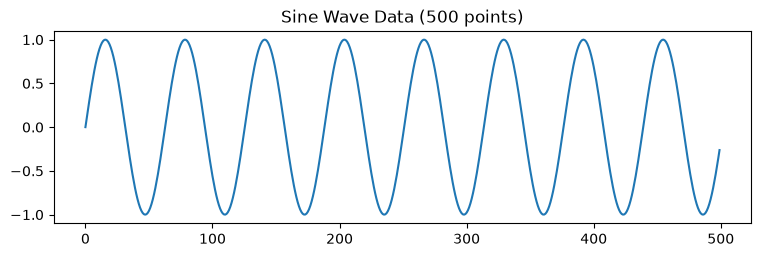

In [4]:
# 수업 코드: 0 ~ 50 구간을 500칸으로 나눠 sin 값 만들기
def gen_sine_wave(seq_len, num_samples):      # 수업 코드 그대로
    x = np.linspace(0, seq_len, num_samples)  # 0 ~ 50, 500개 (끝 포함)
    return np.sin(x)                          # sin 값


data = gen_sine_wave(seq_len=50, num_samples=500)        # 500칸 사인파
step = 50 / (500 - 1)                                    # linspace 칸 간격
print("길이:", len(data), "| 칸 간격:", round(step, 4),  # 간격 · 주기
      "| 한 주기 칸 수:", round(2 * np.pi / step, 1))
print("앞 3개:", data[:3].round(3), "| 최소 · 최대:",    # 값 범위
      data.min().round(3), data.max().round(3))


# 그래프로 확인
plt.figure(figsize=(9, 2.5))              # 가로로 긴 그림
plt.plot(data)                            # 선 그래프
plt.title("Sine Wave Data (500 points)")  # 제목
plt.show()                                # 그림 출력

**결과** · 예측 정답은 약 `62.7`칸 — 칸 간격 0.1002, 2π ÷ 0.1002

- `길이: 500 | 칸 간격: 0.1002 | 한 주기 칸 수: 62.7` — 0 ~ 50을 500칸 → 칸마다 0.1002씩, 약 63칸마다 같은 모양
- `앞 3개: [0.    0.1   0.199] | 최소 · 최대: -1.0 1.0` — sin(0)에서 시작, 범위가 이미 -1 ~ 1이라 수업 코드는 정규화 없이 학습

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>np.linspace(0, 50, 500)</code></td>
<td style="text-align: left;"><strong>개수</strong>를 정함, 끝값 포함</td>
<td style="text-align: left;">구간을 n등분한 시간축 · 그래프 (수업 코드)</td>
</tr>
<tr>
<td style="text-align: left;"><code>np.arange(0, 50, 0.1)</code></td>
<td style="text-align: left;"><strong>간격</strong>을 정함, 끝값 미포함</td>
<td style="text-align: left;">간격이 정해진 시간축</td>
</tr>
<tr>
<td style="text-align: left;">실제 시계열</td>
<td style="text-align: left;">측정 간격이 고정 (1초 · 1일), 잡음 · 추세가 섞임</td>
<td style="text-align: left;">프로젝트 데이터 → 2장부터 <code>make_series()</code>로 흉내</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 실제 시계열은 범위가 제각각(기온 · 매출 · 센서)
> - 정규화가 필요하고, 그때 통계는 train에서만 (2-2)

> ✅ **한 줄 정리** · 시계열을 받으면 길이 · 간격 · 주기 · 범위를 먼저 확인하고 그래프로 본다.

**딥러닝 코드에서는**

- `df["value"].plot()`
- `df.describe()`로 먼저 보고, 주기(하루 24칸 · 일주일 7칸)를 window 길이 후보로 삼음

### 1-2. `A` 슬라이딩 윈도우로 입력 · 정답 만들기 · `create_sequences` · `sliding_window_view` <sub>레이어 실습 create_sequences · NumPy 9-6 · Pandas 9-5</sub>

> 🎯 **긴 시계열 하나를 어떻게 '과거 50칸 → 다음 1칸' 학습 데이터 여러 개로 바꾸는가?**

💡 **쉽게 말하면**

- 시계열 위에 **50칸짜리 창문을 한 칸씩 밀며** 들여다보기.
- 창 안의 50칸이 문제, 창 바로 오른쪽 한 칸이 정답.

<img src="images/rnn2_window.png" alt="슬라이딩 창과 창 안의 hidden state 흐름" width="699">

**실행 흐름**

1. `create_sequences`로 창 · 정답
2. `X` · `y` 모양과 손계산
3. 첫 창 확인
4. NumPy `sliding_window_view` · Pandas `shift`와 비교

**먼저 예측** · 길이 500에서 창 50칸이면 학습 데이터는 몇 개? — 답은 코드 실행 결과 아래에

In [5]:
# 수업 코드: 과거 seq_length칸 → 바로 다음 1칸
def create_sequences(data, seq_length):                           # 수업 코드: 창 → 다음 값
    sequences, labels = [], []                                    # 입력 · 정답 목록
    for i in range(len(data) - seq_length):                       # 창 시작 위치
        sequences.append(data[i:i + seq_length])                  # i ~ i+49 (입력)
        labels.append(data[i + seq_length])                       # i+50 (정답 = 다음 값)
    sequences = torch.tensor(np.array(sequences),                 # 목록 → 실수 텐서
                             dtype=torch.float32).unsqueeze(-1)   # 특성 축
    labels = torch.tensor(np.array(labels), dtype=torch.float32)  # 정답 텐서
    return sequences, labels                                      # (450, 50, 1) · (450,)


X, y = create_sequences(data, seq_length=50)                                        # 창 50칸
print("X", tuple(X.shape), "· y", tuple(y.shape), "| 손계산 500 - 50 =", 500 - 50)  # 모양 · 손계산
print("창 0 = data[0:50]:", np.allclose(X[0, :, 0], data[:50]),                     # 첫 창 확인
      "| 정답 0 = data[50]:", bool(np.isclose(y[0], data[50])))


# 같은 창 · 정답을 NumPy · Pandas로 (NumPy 9-6 · Pandas 9-5)
win = sliding_window_view(data, 50)[:-1]              # 마지막 창은 다음 값이 없음
target = pd.Series(data).shift(-50).dropna()          # 50칸 뒤 값을 당겨 옴
print("NumPy 창 일치:", np.allclose(win, X[..., 0]),  # 세 방법 비교
      "| Pandas shift(-50) 정답 일치:", np.allclose(target, y))

X (450, 50, 1) · y (450,) | 손계산 500 - 50 = 450
창 0 = data[0:50]: True | 정답 0 = data[50]: True
NumPy 창 일치: True | Pandas shift(-50) 정답 일치: True


**결과** · 예측 정답은 `450`개 — 500 - 50 (마지막 창 다음에는 정답이 없음)

- `X (450, 50, 1) · y (450,) | 손계산 500 - 50 = 450` — 창 수 = 길이 - 창 길이, 마지막 축 1 = 칸마다 값 하나 (RNN-1 3-1의 세 겹)
- `창 0 = data[0:50]: True | 정답 0 = data[50]: True` — 입력은 0 ~ 49칸, 정답은 바로 다음 50번 칸
- `NumPy 창 일치: True | Pandas shift(-50) 정답 일치: True` — NumPy · Pandas 정리본의 방법과 같은 결과

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>create_sequences</code> (for + 슬라이싱)</td>
<td style="text-align: left;">창을 하나씩 잘라 리스트로 모음</td>
<td style="text-align: left;">흐름을 눈으로 따라갈 때 (수업 코드)</td>
</tr>
<tr>
<td style="text-align: left;"><code>sliding_window_view</code> (NumPy 9-6)</td>
<td style="text-align: left;">반복문 없이 모든 창을 한 번에, 마지막 창은 정답 없음</td>
<td style="text-align: left;">긴 시계열을 빠르게 자를 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>shift(-k)</code> (Pandas 9-5)</td>
<td style="text-align: left;">표에서 k칸 뒤 값을 당겨 정답 열 만들기</td>
<td style="text-align: left;">날짜 index가 있는 표 데이터</td>
</tr>
<tr>
<td style="text-align: left;"><code>unsqueeze(-1)</code></td>
<td style="text-align: left;"><code>(N, W)</code> → <code>(N, W, 1)</code>, 특성 축 추가</td>
<td style="text-align: left;">값 하나짜리 시계열을 RNN 입력으로 (RNN-1 3-1)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 정답 칸이 입력 창 안에 들어가면(`data[i:i+51]`을 입력으로) 답을 보고 맞히는 셈
> - 입력은 정답 바로 앞까지만

> ✅ **한 줄 정리** · 창 길이 W로 한 칸씩 밀면 `(길이 - W, W, 1)` 입력과 바로 다음 값 정답이 만들어진다.

**딥러닝 코드에서는**

- 다변량(센서 9개)이면 `(창 수, W, 9)`
- RNN-1 UCI HAR가 바로 128칸 창으로 미리 잘라 둔 데이터

### 1-3. `A` 수업 방식 학습과 평가 · `nn.MSELoss` <sub>레이어 실습 학습 · 예측 · 빈칸 2</sub>

> 🎯 **수업 코드처럼 학습에 쓴 데이터로 예측 그래프를 그리면, 그 점수는 무엇을 말해 주는가?**

💡 **쉽게 말하면**

- 학습 데이터로 채점하는 것은 **풀어 본 문제집으로 본 시험**.
- 점수는 높지만 처음 보는 미래 문제를 풀 수 있는지는 알 수 없음.

**실행 흐름**

1. 수업 모델(RNN 2층 · hidden 20)
2. `X` · `y`를 device로
3. 450개 한 번에 100 epoch
4. 같은 450개 예측 · 그래프
5. [빈칸 2] MSE

**수업 모델 모양 추적표** (레이어 실습 요약표, 규칙 설명은 RNN-1 3-3 참조)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">구성</th>
<th style="text-align: left;">입력</th>
<th style="text-align: left;">출력</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">입력</td>
<td style="text-align: left;">사인파 창</td>
<td style="text-align: left;">—</td>
<td style="text-align: left;"><code>(450, 50, 1)</code></td>
</tr>
<tr>
<td style="text-align: left;">RNN 2층</td>
<td style="text-align: left;"><code>nn.RNN(1, 20, num_layers=2)</code></td>
<td style="text-align: left;"><code>(450, 50, 1)</code></td>
<td style="text-align: left;"><code>(450, 50, 20)</code></td>
</tr>
<tr>
<td style="text-align: left;">마지막 칸</td>
<td style="text-align: left;"><code>out[:, -1, :]</code></td>
<td style="text-align: left;"><code>(450, 50, 20)</code></td>
<td style="text-align: left;"><code>(450, 20)</code></td>
</tr>
<tr>
<td style="text-align: left;">출력층</td>
<td style="text-align: left;"><code>nn.Linear(20, 1)</code></td>
<td style="text-align: left;"><code>(450, 20)</code></td>
<td style="text-align: left;"><code>(450, 1)</code></td>
</tr>
</tbody>
</table>

**먼저 예측** · 학습에 쓴 450개로 잰 MSE는 클까 작을까? — 답은 코드 실행 결과 아래에

1/100, loss 0.5682
11/100, loss 0.4500


21/100, loss 0.3049
31/100, loss 0.1291
41/100, loss 0.0624


51/100, loss 0.0305
61/100, loss 0.0149


71/100, loss 0.0072
81/100, loss 0.0043


91/100, loss 0.0035


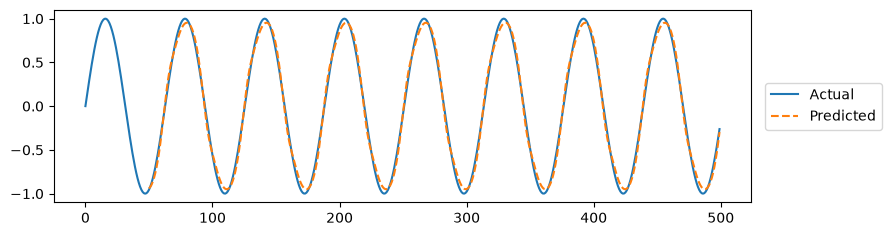

학습에 쓴 450개로 잰 MSE: 0.00290


In [6]:
# 수업 모델: RNN 2층 · hidden 20 → 마지막 칸 → Linear(20 → 1)
class RNNModel(nn.Module):                                      # 수업 모델
    def __init__(self, input_size, hidden_size, num_layers):    # 입력 · hidden · 층
        super().__init__()                                      # nn.Module 준비 (필수)
        self.rnn = nn.RNN(input_size, hidden_size, num_layers,  # RNN 층
                          batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)                     # 마지막 요약 → 값 1개

    def forward(self, x):              # 입력이 지나가는 길
        out, _ = self.rnn(x)           # (450, 50, 20)
        return self.fc(out[:, -1, :])  # (450, 20) → (450, 1)


set_seed()                                            # 모델마다 같은 시작점
model = RNNModel(1, 20, 2).to(DEV)                    # 수업 설정
X_d, y_d = X.to(DEV), y.to(DEV)                       # 원본은 이 줄이 없어 GPU에서 에러
loss_fn = nn.MSELoss()                                # 회귀 손실
opt = torch.optim.Adam(model.parameters(), lr=0.001)  # 수업 학습률


# 수업 학습: 450개 전체를 한 번에 · 100 epoch
for epoch in range(100):                                   # 100 epoch
    outputs = model(X_d)                                   # 450개 한 번에 예측
    loss = loss_fn(outputs.squeeze(), y_d)                 # (450, 1) → (450,)
    opt.zero_grad()                                        # 지난 기울기 지우기
    loss.backward()                                        # 기울기
    opt.step()                                             # 가중치 한 걸음 수정
    if epoch % 10 == 0:                                    # 10번마다 출력
        print(f"{epoch + 1}/100, loss {loss.item():.4f}")  # loss 기록


# 학습에 쓴 450개를 그대로 예측 → 그래프
model.eval()                                               # 평가 모드
with torch.no_grad():                                      # 평가는 기울기 기록 안 함
    preds = model(X_d).cpu().numpy()                       # GPU 텐서는 .cpu() 후 numpy
plt.figure(figsize=(9, 2.5))                               # 가로로 긴 그림
plt.plot(data, label="Actual")                             # 실제
plt.plot(range(50, 50 + len(preds)), preds, "--", label="Predicted")  # 예측 (50칸 뒤부터)
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))  # 범례는 그림 밖 (선을 가리지 않게)
plt.show()                                                 # 그림 출력


# [빈칸 2 정답] 원본 맨 끝 빈 셀 → 예측을 숫자로 평가
print(f"학습에 쓴 450개로 잰 MSE: {mse(preds[:, 0], y.numpy()):.5f}")  # 빈칸 2: 숫자 평가

**결과** · 예측 정답은 아주 작음 — `0.00290`. 그래프도 거의 겹치지만 처음 보는 구간 성적이 아님

- `1/100, loss 0.5682` — 처음 loss
- `91/100, loss 0.0035` — 100 epoch 동안 loss가 꾸준히 줄어듦
- `학습에 쓴 450개로 잰 MSE: 0.00290` — [빈칸 2] 외운 문제로 본 시험 점수 → 실력은 2 · 3장처럼 미래 구간으로 확인

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">학습 데이터로 평가 (수업 코드)</td>
<td style="text-align: left;">외운 문제로 본 시험 → 점수가 좋게 나옴</td>
<td style="text-align: left;">코드가 도는지 확인할 때만</td>
</tr>
<tr>
<td style="text-align: left;">시간순 test로 평가 (3-1)</td>
<td style="text-align: left;">처음 보는 미래 구간으로 채점</td>
<td style="text-align: left;">실력을 보고할 때 (<strong>항상</strong>)</td>
</tr>
<tr>
<td style="text-align: left;">전체 배치 (450개 한 번에)</td>
<td style="text-align: left;">epoch마다 업데이트 1번</td>
<td style="text-align: left;">데이터가 아주 작을 때</td>
</tr>
<tr>
<td style="text-align: left;">미니배치 (보강 <code>fit</code>)</td>
<td style="text-align: left;">epoch마다 업데이트 여러 번 · GPU 메모리 절약</td>
<td style="text-align: left;">보통 학습 (<strong>기본 선택</strong>)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 원본은 모델만 `.to(device)` 하고 `X`
> - `y`는 CPU에 둬서 GPU에서는 `RuntimeError`
> - 모델과 데이터를 같은 device로, 결과는 `.cpu()` 후 `.numpy()`

> ✅ **한 줄 정리** · 학습에 쓴 데이터로 잰 오차는 외운 정도일 뿐이라, 시계열은 시간순으로 떼어 둔 미래 구간으로 평가해야 한다.

**딥러닝 코드에서는**

- `model.to(DEV)`
- `x.to(DEV)`를 함께, 예측 결과는 `pred.cpu().numpy()`
- 모양 규칙(`out` · `h_n`)은 RNN-1 3-3

---
## 2. 나누기와 정규화 (보강)

> **이 장의 흐름**
>
> - 1장은 학습에 쓴 데이터로 채점했다
> - 처음 보는 미래로 채점하려면 미래를 먼저 떼어 두고, 그 미래 정보가 분할 · 정규화로 새지 않게 해야 함

**파이프라인 위치** · ② 시간순 분할 → ③ 정규화

### 2-1. `A` 무작위 분할 vs 시간순 분할 · `idx < n_tr` <sub>보강 · 머신러닝-1 데이터 분할과 연결</sub>

> 🎯 **시계열 창을 무작위로 섞어 train · val로 나누면 무엇이 새어 들어가는가?**

💡 **쉽게 말하면**

- 창끼리는 49칸이 겹치는 **이웃**.
- 섞어서 나누면 검증 창의 정답 칸을 옆 학습 창이 입력으로 이미 봐서, 시험 문제의 답이 문제집에 실려 있는 셈.

<img src="images/rnn2_split.png" alt="시간순 분할과 무작위 분할" width="892">

**실행 흐름**

1. 잡음 섞인 사인파 1200칸
2. 창 50칸
3. 정답 위치로 70% · 15% · 15% 시간순 분할
4. 같은 개수로 무작위 분할
5. 누수 비율 · 그림

**먼저 예측** · 무작위로 나누면 검증 정답 중 몇 %가 학습 창의 입력에 이미 들어 있을까? — 답은 코드 실행 결과 아래에

창 1150 → train 790 · val 180 · test 180
검증 정답이 학습 입력에 이미 있음 → 무작위 1.000 · 시간순 0.000


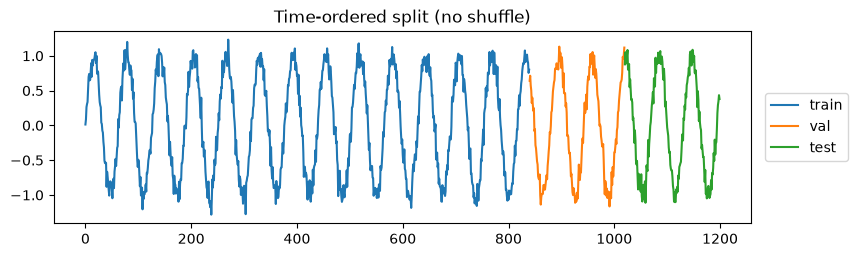

In [7]:
# [보강] 잡음 섞인 사인파 1200칸 (추세는 5장) → 창 50칸
series = make_series(noise=0.1)            # 잡음 사인파 1200칸
n = len(series)                            # 1200
n_tr, n_va = int(n * 0.70), int(n * 0.85)  # 840 · 1020 (경계 위치)
W = 50                                     # 창 길이
_, _, idx = make_windows(series, W)        # 정답 위치만 먼저


# 시간순 분할: 정답 위치로 나눔 → 과거로 배우고 미래로 평가
tr, va, te = idx < n_tr, (idx >= n_tr) & (idx < n_va), idx >= n_va  # 정답 위치로 시간순 분할
print("창", len(idx), "→ train", tr.sum(), "· val", va.sum(),       # 분할 개수
      "· test", te.sum())


# 무작위 분할: test 앞 구간의 창을 섞어 같은 개수로 나눔
pool = np.where(idx < n_va)[0]                     # test 앞 구간 창
perm = np.random.default_rng(0).permutation(pool)  # 섞기 (비교용)
r_tr, r_va = perm[:tr.sum()], perm[tr.sum():]      # 같은 개수로 나눔


# 누수 확인: 검증 정답 칸이 학습 창의 입력에 이미 들어 있는 비율
def leak_rate(train_rows, val_rows):                    # 누수 비율
    seen = set()                                        # 학습 창이 본 칸
    for i in idx[train_rows]:                           # 학습 창마다
        seen.update(range(i - W, i))                    # 이 학습 창이 입력으로 본 칸
    return np.mean([i in seen for i in idx[val_rows]])  # 검증 정답 중 이미 본 비율


print(f"검증 정답이 학습 입력에 이미 있음 → 무작위 {leak_rate(r_tr, r_va):.3f}"  # 두 분할 비교
      f" · 시간순 {leak_rate(tr, va):.3f}")


# 시간순 분할 그림: 앞 70% train · 다음 15% val · 마지막 15% test
plt.figure(figsize=(9, 2.5))                               # 가로로 긴 그림
for (a, b), name in [((0, n_tr), "train"), ((n_tr, n_va), "val"),  # 구간마다 다른 색
                     ((n_va, n), "test")]:
    plt.plot(range(a, b), series[a:b], label=name)         # 구간 그리기
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))  # 범례는 그림 밖 (선을 가리지 않게)
plt.title("Time-ordered split (no shuffle)")               # 제목
plt.show()                                                 # 그림 출력

**결과** · 예측 정답은 `100%` — 전부. 시간순 분할은 `0%`

- `창 1150 → train 790 · val 180 · test 180` — 1200 - 50 = 1150창을 정답 위치로 앞 70% · 다음 15% · 끝 15%
- `검증 정답이 학습 입력에 이미 있음 → 무작위 1.000 · 시간순 0.000` — 무작위면 검증 정답 칸을 학습 창이 모두 입력으로 이미 봄, 시간순은 하나도 안 봄

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">무작위 분할</td>
<td style="text-align: left;">창을 섞어 나눔 → 검증 정답이 학습 창 입력에 이미 들어감</td>
<td style="text-align: left;">순서가 없는 표 · 이미지 데이터</td>
</tr>
<tr>
<td style="text-align: left;">시간순 분할</td>
<td style="text-align: left;">앞 train → 다음 val → 끝 test, 섞지 않음</td>
<td style="text-align: left;">시계열 (<strong>항상</strong>)</td>
</tr>
<tr>
<td style="text-align: left;">학습 중 창 섞기 (<code>randperm</code>)</td>
<td style="text-align: left;">train 안에서 배치 순서만 바뀜, 창 안 순서는 그대로</td>
<td style="text-align: left;">학습할 때 (누수 아님)</td>
</tr>
<tr>
<td style="text-align: left;"><code>TimeSeriesSplit</code> (sklearn)</td>
<td style="text-align: left;">시간순을 지키며 여러 번 나눠 재기</td>
<td style="text-align: left;">데이터가 적어 한 번 나누기가 불안할 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 분할은 시간순으로 하고, 학습 중 배치 순서만 섞는 `randperm`
> - `shuffle=True`는 train 안에서라 괜찮음 (헷갈리지 않기)

> ✅ **한 줄 정리** · 시계열은 창을 섞어 나누면 검증 정답이 학습 입력에 새어 들어가므로, 정답 위치 기준으로 과거 → 미래 순서로 나눈다.

**딥러닝 코드에서는**

- `train = df[df.date < "2026-07-01"]`
- `val = ...` 처럼 날짜로 자름 (`train_test_split(shuffle=False)`도 같은 뜻)

### 2-2. `A` 전체 통계 vs train 통계 정규화 · `(x - mu) / sd` <sub>보강 · RNN-1 5-1 · 머신러닝-2 누수와 연결</sub>

> 🎯 **정규화 평균 · 표준편차를 전체 데이터로 계산하면 시계열에서 무엇이 달라지는가?**

💡 **쉽게 말하면**

- 평균은 **반 전체 평균 키**.
- 추세가 있으면(키가 계속 자라면) 미래 학생까지 넣은 평균은 지금 반 평균보다 큼 — 미래 정보를 미리 본 것.

**실행 흐름**

1. 추세 없음 · 있음 두 시계열에서 train 평균과 전체 평균 비교
2. test를 각 기준으로 바꾼 평균
3. 본 실험을 train 통계로 정규화
4. 되돌리기 확인

**먼저 예측** · 추세가 있는 시계열에서 전체 평균은 train 평균보다 클까 작을까? — 답은 코드 실행 결과 아래에

In [8]:
# [보강] 추세가 있으면 train 평균과 전체 평균이 달라짐
trend_s = make_series(noise=0.1, trend=0.002)                            # 추세 있는 시계열
for name, s in [("추세 없음", series), ("추세 있음", trend_s)]:          # 두 시계열 비교
    mu_tr, sd_tr = s[:n_tr].mean(), s[:n_tr].std()                       # train 구간만
    mu_all, sd_all = s.mean(), s.std()                                   # test 까지 포함 (누수)
    z_tr = (s[n_va:] - mu_tr) / sd_tr                                    # train 기준으로 바꾼 test
    z_all = (s[n_va:] - mu_all) / sd_all                                 # 전체 기준으로 바꾼 test
    print(f"{kpad(name, 9)} 평균 train {mu_tr:.3f} · 전체 {mu_all:.3f}"  # 평균 · test 위치
          f" | test(z) train 기준 {z_tr.mean():.2f}"
          f" · 전체 기준 {z_all.mean():.2f}")


# 본 실험(추세 없음): train 통계로 정규화 → 창 만들기
mu, sd = series[:n_tr].mean(), series[:n_tr].std()  # train 통계만
z = (series - mu) / sd                              # 전체를 train 기준으로
X, Y, idx = make_windows(z, W)                      # X (1150, 50) · Y (1150, 1)


def inv(a):             # 정규화 되돌리기 → 원래 단위로 평가
    return a * sd + mu  # 원래 단위


print(f"z train 평균 {z[:n_tr].mean():.3f} · 표준편차 {z[:n_tr].std():.3f}"  # 확인
      f" | 되돌리기 최대 오차 {np.abs(inv(z) - series).max():.1e}")

추세 없음 평균 train 0.017 · 전체 -0.002 | test(z) train 기준 -0.07 · 전체 기준 -0.04
추세 있음 평균 train 0.856 · 전체 1.197 | test(z) train 기준 1.55 · 전체 기준 1.02
z train 평균 -0.000 · 표준편차 1.000 | 되돌리기 최대 오차 2.2e-16


**결과** · 예측 정답은 큼 — train `0.856` · 전체 `1.197`. 뒤쪽(미래)의 큰 값이 섞임

- `추세 없음 평균 train 0.017 · 전체 -0.002 | test(z) train 기준 -0.07 · 전체 기준 -0.04` — 추세가 없으면 두 평균이 거의 같음
- `추세 있음 평균 train 0.856 · 전체 1.197 | test(z) train 기준 1.55 · 전체 기준 1.02` — 전체 기준이면 test가 1.02로 덜 튀어 보임 → 실제 상황(train 기준 1.55)보다 쉬운 시험이 됨
- `z train 평균 -0.000 · 표준편차 1.000 | 되돌리기 최대 오차 2.2e-16` — 되돌리기(× sd + mu)는 정확 → 예측을 원래 단위로 바꿔 평가

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">train 통계로 정규화</td>
<td style="text-align: left;">train 평균 · 표준편차만 사용 → test는 0 · 1에서 벗어날 수 있음</td>
<td style="text-align: left;"><strong>항상</strong> (추론 때도 같은 값 저장해 사용)</td>
</tr>
<tr>
<td style="text-align: left;">전체 통계로 정규화</td>
<td style="text-align: left;">test(미래) 값이 평균에 섞임</td>
<td style="text-align: left;">쓰지 않음 (평가가 실제보다 쉬워 보임)</td>
</tr>
<tr>
<td style="text-align: left;">되돌리기 <code>× sd + mu</code></td>
<td style="text-align: left;">예측을 원래 단위로</td>
<td style="text-align: left;">MSE · MAE를 원래 단위로 보고할 때</td>
</tr>
<tr>
<td style="text-align: left;">차분 (5장)</td>
<td style="text-align: left;">값 대신 변화량 <code>오늘 - 어제</code></td>
<td style="text-align: left;">추세가 있어 미래 값이 train 범위를 벗어날 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - train 통계로 바꾼 test는 평균 0
> - 표준편차 1이 아닌 것이 정상
> - 억지로 맞추면 누수

> ✅ **한 줄 정리** · 정규화 통계는 train 구간에서만 계산해 val · test · 추론에 그대로 쓰고, 예측은 되돌려 원래 단위로 평가한다.

**딥러닝 코드에서는**

- `mu, sd = train.mean(), train.std()` → 저장(`torch.save`나 JSON) → 추론 때 같은 값으로 `(x - mu) / sd`

---
## 3. 학습과 평가 (보강)

> **이 장의 흐름**
>
> - 2장에서 미래를 떼어 두고 정규화했다
> - 이제 학습하고, 공짜 예측(기준선)과 같은 자 · 같은 단위로 비교

**파이프라인 위치** · ⑤ 학습 → ⑥ 평가

### 3-1. `A` 기준선과 비교하기 · `shift(1)` · `rolling(k)` <sub>보강 · Pandas 9-5 shift · rolling</sub>

> 🎯 **시간순으로 학습한 GRU는 '직전 값' · '이동 평균' 기준선보다 얼마나 나은가?**

💡 **쉽게 말하면**

- 기준선은 **내일 날씨 = 오늘 날씨** 같은 공짜 예측.
- 모델이 공짜 예측도 못 이기면 쓸 이유가 없음.

**실행 흐름**

1. 시간순 분할로 GRU 학습(val로 epoch 고름)
2. 무작위 분할 모델과 val · test 점수 비교
3. `shift(1)` · `rolling(k)` 기준선
4. test MSE · MAE 표 · 그림

**먼저 예측** · 직전 값 기준선의 test MSE는 GRU보다 클까? — 답은 코드 실행 결과 아래에

시간순 · 가장 좋은 epoch 78 · val MSE 0.0091 · test MSE 0.0107


무작위 · val MSE 0.0097 · test MSE 0.0110
test 180칸      MSE     MAE
직전 값       0.0255  0.1311
이동 평균 3   0.0311  0.1478
이동 평균 10  0.1473  0.3412
GRU           0.0107  0.0843


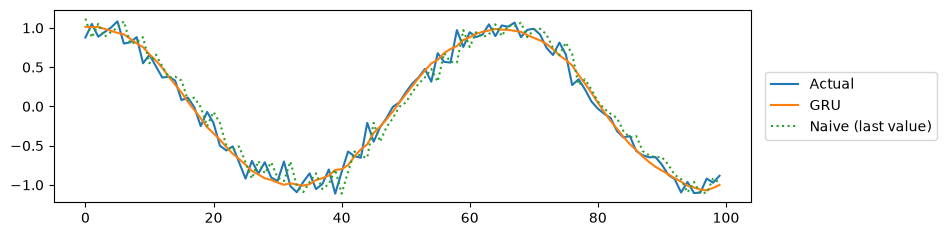

In [9]:
# [보강] 시간순 분할로 학습 (val MSE가 가장 낮은 epoch 사용)
m_one, best_ep = fit(X[tr], Y[tr], X[va], Y[va])                 # 시간순 학습
p_te, y_te = inv(predict(m_one, X[te])[:, 0]), inv(Y[te][:, 0])  # test 예측 · 정답 (원래 단위)
p_va = inv(predict(m_one, X[va])[:, 0])                          # val 예측
print(f"시간순 · 가장 좋은 epoch {best_ep}"                      # val · test
      f" · val MSE {mse(p_va, inv(Y[va][:, 0])):.4f}"
      f" · test MSE {mse(p_te, y_te):.4f}")


# 무작위 분할로 학습 → 자기 val 점수와 미래(test) 점수
m_rand, _ = fit(X[r_tr], Y[r_tr], X[r_va], Y[r_va])             # 무작위 분할 학습
pr_va = inv(predict(m_rand, X[r_va])[:, 0])                     # 자기 val 예측
pr_te = inv(predict(m_rand, X[te])[:, 0])                       # 미래 test 예측
print(f"무작위 · val MSE {mse(pr_va, inv(Y[r_va][:, 0])):.4f}"  # 두 점수
      f" · test MSE {mse(pr_te, y_te):.4f}")


# 기준선: 직전 값 shift(1) · 이동 평균 rolling(k) (Pandas 9-5)
s = pd.Series(series)                                                  # Pandas로
t_idx = idx[te]                                                        # test 정답 위치
base = {"직전 값": s.shift(1),                                         # 기준선 3개
        "이동 평균 3": s.rolling(3).mean().shift(1),
        "이동 평균 10": s.rolling(10).mean().shift(1)}
print(kpad("test 180칸", 13), "  MSE     MAE")                         # 머리글
for name, pred in [*base.items(), ("GRU", None)]:                      # 기준선 + GRU
    p = p_te if pred is None else pred.values[t_idx]                   # test 위치 값만
    print(f"{kpad(name, 13)} {mse(p, y_te):.4f}  {mae(p, y_te):.4f}")  # 같은 자로 비교


# test 앞 100칸 그림
plt.figure(figsize=(9, 2.5))                               # 가로로 긴 그림
plt.plot(y_te[:100], label="Actual")                       # 실제
plt.plot(p_te[:100], label="GRU")                          # GRU
plt.plot(base["직전 값"].values[t_idx][:100], ":", label="Naive (last value)")  # 직전 값
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))  # 범례는 그림 밖 (선을 가리지 않게)
plt.show()                                                 # 그림 출력

**결과** · 예측 정답은 큼 — 직전 값 `0.0255` · GRU `0.0107`

- `시간순 · 가장 좋은 epoch 78 · val MSE 0.0091 · test MSE 0.0107` — val로 고른 가중치, val과 test가 가까움 → val이 미래 성능을 잘 대신함
- `무작위 · val MSE 0.0097 · test MSE 0.0110` — 이 데이터는 패턴이 처음부터 끝까지 같아 점수 차이는 작음 → 누수 여부는 점수가 아니라 2-1처럼 구조로 확인
- `직전 값 0.0255 0.1311` — 가장 단순한 기준선
- `이동 평균 10 0.1473 0.3412` — 10칸 평균은 파도 모양을 뭉개 가장 나쁨 (3칸은 `0.0311`)
- `GRU 0.0107 0.0843` — 직전 값보다 MSE 58% 낮음, 잡음 분산(0.1의 제곱 0.01)에 가까움 → 잡음 말고는 거의 다 맞힘

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">직전 값 <code>shift(1)</code></td>
<td style="text-align: left;">어제 값 = 오늘 예측</td>
<td style="text-align: left;">모든 시계열의 <strong>첫</strong> 기준선</td>
</tr>
<tr>
<td style="text-align: left;">이동 평균 <code>rolling(k).mean().shift(1)</code></td>
<td style="text-align: left;">최근 k칸 평균, k가 크면 모양을 뭉갬</td>
<td style="text-align: left;">잡음이 크고 천천히 변할 때</td>
</tr>
<tr>
<td style="text-align: left;">GRU</td>
<td style="text-align: left;">과거 W칸의 패턴을 학습</td>
<td style="text-align: left;">기준선을 확실히 넘어야 의미</td>
</tr>
<tr>
<td style="text-align: left;">val로 epoch 고르기</td>
<td style="text-align: left;">epoch마다 val MSE → 가장 낮은 가중치</td>
<td style="text-align: left;">test는 마지막 한 번만 (보고용)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `rolling(k).mean()`을 `shift(1)` 없이 쓰면 오늘 값이 평균에 들어가 정답을 보고 예측
> - 기준선도 과거만

> ✅ **한 줄 정리** · 모델 점수는 직전 값 · 이동 평균 기준선과 같은 test 구간 · 같은 단위로 나란히 놓아야 의미가 있다.

**딥러닝 코드에서는**

- 보고 표 예 · `직전 값 MSE 0.0255 / GRU 0.0107 (val로 epoch 선택, test 1회)`
- 기준선 없는 시계열 점수는 해석 불가

### 3-2. `B` MSE vs MAE · `nn.L1Loss` <sub>보강</sub>

> 🎯 **같은 예측 오차를 MSE와 MAE로 재면 무엇이 다르고, 튀는 오차 하나에는 각각 어떻게 반응하는가?**

💡 **쉽게 말하면**

- MSE는 **큰 실수에 벌금을 제곱으로** 매기고, MAE는 **실수한 만큼만** 매김.
- 한 번 크게 틀리면 MSE가 훨씬 크게 뜀.

<img src="images/rnn2_mse_mae.png" alt="튀는 오차 하나에 대한 MSE · MAE" width="810">

**실행 흐름**

1. GRU test 오차로 MSE · MAE · RMSE
2. 오차 하나만 +3
3. 배율 비교
4. `nn.MSELoss` · `nn.L1Loss`로 같은 오차 재기

**먼저 예측** · 180개 중 하나만 3만큼 틀리면 MSE와 MAE 중 어느 쪽이 더 크게 변할까? — 답은 코드 실행 결과 아래에

In [10]:
# [보강] 같은 예측 오차를 두 가지 자로 재기
err = p_te - y_te                                                            # 오차
print(f"GRU   MSE {np.mean(err ** 2):.4f} · MAE {np.mean(np.abs(err)):.4f}"  # 세 지표
      f" · RMSE {np.sqrt(np.mean(err ** 2)):.4f}")


# 180개 중 하나만 3만큼 크게 틀리면 (센서가 한 번 튐)
bad = err.copy()                                  # 원본 보존
bad[0] += 3                                       # 한 칸만 크게 틀림
print(f"하나만 +3 → MSE {np.mean(bad ** 2):.4f}"  # 배율 비교
      f" ({np.mean(bad ** 2) / np.mean(err ** 2):.1f}배)"
      f" · MAE {np.mean(np.abs(bad)):.4f}"
      f" ({np.mean(np.abs(bad)) / np.mean(np.abs(err)):.1f}배)")


# 손실 함수로 쓰면: MSE = 큰 오차에 큰 벌, MAE(L1) = 오차 크기만큼
e = torch.tensor([0.1, 0.5, 3.0])                            # 작은 · 중간 · 큰 오차
for name, fn in [("MSELoss", nn.MSELoss(reduction="none")),  # 칸별 손실
                 ("L1Loss", nn.L1Loss(reduction="none"))]:
    print(f"{name:<8} 오차 0.1 · 0.5 · 3.0 →",               # 손실 값
          [round(v, 3) for v in fn(e, torch.zeros(3)).tolist()])

GRU   MSE 0.0107 · MAE 0.0843 · RMSE 0.1036
하나만 +3 → MSE 0.0653 (6.1배) · MAE 0.1010 (1.2배)
MSELoss  오차 0.1 · 0.5 · 3.0 → [0.01, 0.25, 9.0]
L1Loss   오차 0.1 · 0.5 · 3.0 → [0.1, 0.5, 3.0]


**결과** · 예측 정답은 MSE — 6.1배, MAE는 1.2배

- `GRU   MSE 0.0107 · MAE 0.0843 · RMSE 0.1036` — RMSE = √MSE → 원래 값과 같은 단위
- `하나만 +3 → MSE 0.0653 (6.1배) · MAE 0.1010 (1.2배)` — 튀는 오차 하나에 MSE는 크게 뛰고 MAE는 조금만
- `MSELoss  오차 0.1 · 0.5 · 3.0 → [0.01, 0.25, 9.0]` — 제곱이라 1보다 작은 오차는 더 작게, 큰 오차는 훨씬 크게
- `L1Loss   오차 0.1 · 0.5 · 3.0 → [0.1, 0.5, 3.0]` — 오차 크기 그대로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">MSE</td>
<td style="text-align: left;">제곱 → 큰 오차에 큰 벌, 단위는 값²</td>
<td style="text-align: left;">큰 오차가 특히 나쁠 때 · 기본 학습 손실</td>
</tr>
<tr>
<td style="text-align: left;">MAE</td>
<td style="text-align: left;">절댓값 → 오차 크기 그대로, 단위는 값</td>
<td style="text-align: left;">튀는 값(이상치)이 섞일 때 · 사람에게 보고</td>
</tr>
<tr>
<td style="text-align: left;">RMSE</td>
<td style="text-align: left;">√MSE → 단위가 값</td>
<td style="text-align: left;">MSE를 원래 단위로 보고할 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.SmoothL1Loss</code> (Huber)</td>
<td style="text-align: left;">작은 오차는 제곱, 큰 오차는 절댓값</td>
<td style="text-align: left;">이상치가 가끔 있는 회귀 학습</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - MSE는 단위가 값의 제곱(°C²)이라 그대로 읽기 어려움
> - 보고는 RMSE · MAE로

> ✅ **한 줄 정리** · MSE는 큰 오차에 민감하고 MAE는 고르게 반영하므로, 이상치가 있으면 둘을 함께 보고한다.

**딥러닝 코드에서는**

- 학습 손실은 보통 `nn.MSELoss()`, 센서가 가끔 튀면 `nn.SmoothL1Loss()`, 보고는 MAE · RMSE

---
## 4. 예측 방식 (보강)

> **이 장의 흐름**
>
> - 3장까지는 다음 1칸 · 창 50칸이었다
> - 여러 칸 앞을 예측하는 방법과 과거를 몇 칸 볼지를 바꿔 같은 조건에서 비교

**파이프라인 위치** · ④ 창 만들기 → ⑥ 평가

### 4-1. `A` 한 걸음 vs 여러 걸음 예측 · `Linear(hid, H)` <sub>보강</sub>

> 🎯 **다음 1칸이 아니라 다음 20칸을 예측해야 하면 어떤 방법이 있고, 걸음이 멀어질수록 오차는 어떻게 되는가?**

💡 **쉽게 말하면**

- 재귀는 **내 예측을 다시 사실처럼 믿고** 한 칸씩 나아가기, 직접은 **20칸 답안지를 한 번에** 쓰기.
- 직전 값 고정은 지금 값을 20칸 내내 그대로 두기.

<img src="images/rnn2_multistep.png" alt="재귀와 직접 여러 걸음 예측" width="728">

**실행 흐름**

1. 창 50
2. 정답 20칸 데이터
3. 재귀(3-1 모델 20번) · 직접(출력 20개 모델) · 직전 값 고정
4. 걸음 h = 1 · 5 · 10 · 20의 MAE · 그림

**먼저 예측** · 직전 값 고정 기준선은 20칸 뒤에 MAE가 어떻게 될까? — 답은 코드 실행 결과 아래에

시작 161 곳 · 걸음별 MAE
방법             h=1     h=5    h=10    h=20
재귀           0.084   0.088   0.089   0.085
직접           0.083   0.087   0.086   0.091
직전 값 고정   0.131   0.321   0.614   1.069


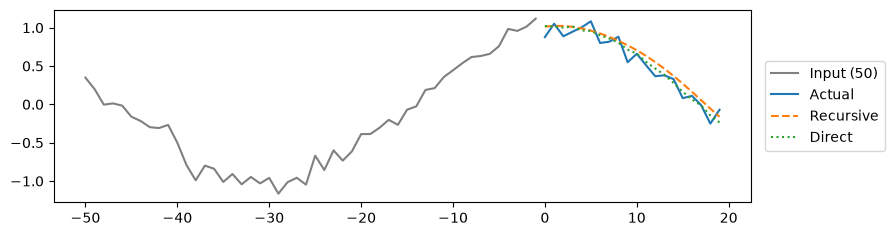

In [11]:
# [보강] 여러 걸음(H = 20칸) 예측 세 가지
H = 20                                 # 예측할 칸 수
XH, YH, iH = make_windows(z, W, H)     # 정답 20칸 창
trH = iH + H <= n_tr                   # 정답 20칸 모두 train 구간
vaH = (iH >= n_tr) & (iH + H <= n_va)  # 정답 20칸 모두 val
teH = iH >= n_va                       # test 시작점
truth = inv(YH[teH])                   # (161, 20)


# 방법 1 재귀: 한 걸음 모델의 예측을 창 끝에 붙여 20번 반복
def recursive(model, X0, H):                                  # 한 걸음 모델을 H번
    Xc, outs = X0.copy(), []                                  # 창 복사 · 결과
    for _ in range(H):                                        # H번
        p = predict(model, Xc)[:, 0]                          # 다음 1칸
        outs.append(p)                                        # 예측 저장
        Xc = np.concatenate([Xc[:, 1:], p[:, None]], axis=1)  # 한 칸 밀기
    return np.stack(outs, axis=1)                             # (N, H)


rec = inv(recursive(m_one, XH[teH], H))  # 재귀 예측


# 방법 2 직접: 다음 20칸을 한 번에 내는 모델 (출력 20개)
m_dir, _ = fit(XH[trH], YH[trH], XH[vaH], YH[vaH], H=H)  # 직접 모델 (출력 20)
dirp = inv(predict(m_dir, XH[teH]))                      # 직접 예측


# 기준선: 마지막 값을 20칸 내내 그대로
naive = np.repeat(series[iH[teH] - 1][:, None], H, axis=1)                       # 마지막 값 20번
print("시작", teH.sum(), "곳 · 걸음별 MAE")                                      # 시작점 수
print(kpad("방법", 12) + "".join(f"{f'h={h}':>8}" for h in (1, 5, 10, 20)))      # 머리글
for name, p in [("재귀", rec), ("직접", dirp), ("직전 값 고정", naive)]:         # 세 방법
    print(kpad(name, 12) + "".join(f"{mae(p[:, h - 1], truth[:, h - 1]):>8.3f}"  # 걸음별 MAE
                                   for h in (1, 5, 10, 20)))


# test 첫 시작점에서 20칸 예측 그림
plt.figure(figsize=(9, 2.5))                               # 가로로 긴 그림
plt.plot(range(-W, 0), inv(XH[teH][0]), color="gray", label="Input (50)")  # 입력 창
plt.plot(truth[0], label="Actual")                         # 실제 20칸
plt.plot(rec[0], "--", label="Recursive")                  # 재귀
plt.plot(dirp[0], ":", label="Direct")                     # 직접
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))  # 범례는 그림 밖 (선을 가리지 않게)
plt.show()                                                 # 그림 출력

**결과** · 예측 정답은 크게 나빠짐 — `0.131` → `1.069`. 파도가 움직이는데 값을 고정했기 때문

- `시작 161 곳 · 걸음별 MAE` — test 구간에서 정답 20칸이 끝까지 들어가는 시작점 수 180 - 20 + 1 = 161
- `재귀 0.084 0.088 0.089 0.085` — 한 걸음 모델을 20번 반복해도 오차가 거의 안 커짐 (규칙이 일정한 파도라서)
- `직접 0.083 0.087 0.086 0.091` — 20칸을 한 번에 — 이 데이터에서는 재귀와 비슷
- `직전 값 고정 0.131 0.321 0.614 1.069` — 멀리 갈수록 급격히 나빠짐 → 여러 걸음에서 모델과의 차이가 커짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">한 걸음 예측</td>
<td style="text-align: left;">다음 1칸, 매번 실제 값으로 창을 채움</td>
<td style="text-align: left;">실제 값이 계속 들어오는 실시간 예측</td>
</tr>
<tr>
<td style="text-align: left;">재귀 여러 걸음</td>
<td style="text-align: left;">예측을 다시 입력 → 오차가 쌓일 수 있음</td>
<td style="text-align: left;">모델 하나로 길이를 자유롭게</td>
</tr>
<tr>
<td style="text-align: left;">직접 여러 걸음</td>
<td style="text-align: left;">출력 H개를 한 번에 (<code>Linear(hid, H)</code>)</td>
<td style="text-align: left;">예측 길이가 정해져 있을 때</td>
</tr>
<tr>
<td style="text-align: left;">직전 값 고정</td>
<td style="text-align: left;">마지막 값을 H칸 내내</td>
<td style="text-align: left;">여러 걸음 예측의 기준선</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 재귀는 예측 오차가 다음 입력으로 들어가 쌓일 수 있음
> - 이 실험처럼 안 쌓일 때도 있으니 걸음별 오차를 꼭 재기

> ✅ **한 줄 정리** · 여러 걸음 예측은 재귀(한 걸음 반복)나 직접(출력 H개)으로 하고, 걸음별 오차를 기준선과 함께 비교한다.

**딥러닝 코드에서는**

- 직접 방식은 마지막 층만 `nn.Linear(hidden, H)`로 바꾸면 됨, 학습 정답도 `(N, H)` 모양

### 4-2. `B` window 길이 짧게 vs 길게 · `make_windows(z, W)` <sub>보강 · RNN-1 4-1 거리와 연결</sub>

> 🎯 **과거를 몇 칸 보게 할지(window)는 성능에 어떤 영향을 주며, 어떻게 정하는가?**

💡 **쉽게 말하면**

- window는 **차창 밖을 보는 거리**.
- 너무 짧으면 오르막인지 내리막인지 모르고, 길면 정보는 많지만 학습 창 수가 줄고 계산이 늘어남.

<img src="images/rnn2_window_len.png" alt="window 길이별 test MSE" width="681">

**실행 흐름**

1. window 5 · 20 · 50 · 100
2. 같은 분할 · 같은 학습 함수 · 같은 test 180칸
3. test MSE

**먼저 예측** · window 5(한 주기의 8%)와 50 중 어느 쪽이 나을까? — 답은 코드 실행 결과 아래에

In [12]:
# [보강] window 길이만 바꾸고 나머지는 같게 (test 180칸은 모두 같음)
for W2 in [5, 20, 50, 100]:                                             # 창 길이 4가지
    X2, Y2, i2 = make_windows(z, W2)                                    # 창 다시 만들기
    a, b, c = i2 < n_tr, (i2 >= n_tr) & (i2 < n_va), i2 >= n_va         # 같은 시간순 분할
    m2, _ = fit(X2[a], Y2[a], X2[b], Y2[b])                             # 같은 학습
    p2 = inv(predict(m2, X2[c])[:, 0])                                  # test 예측
    print(f"window {W2:>3} · 한 주기의 {W2 / (2 * np.pi / 0.1):.2f}배"  # 결과
          f" · train 창 {a.sum()} · test {c.sum()}칸"
          f" · test MSE {mse(p2, inv(Y2[c][:, 0])):.4f}")

window   5 · 한 주기의 0.08배 · train 창 835 · test 180칸 · test MSE 0.0167


window  20 · 한 주기의 0.32배 · train 창 820 · test 180칸 · test MSE 0.0107


window  50 · 한 주기의 0.80배 · train 창 790 · test 180칸 · test MSE 0.0107


window 100 · 한 주기의 1.59배 · train 창 740 · test 180칸 · test MSE 0.0106


**결과** · 예측 정답은 50 — `0.0167` vs `0.0107`

- `window   5 · 한 주기의 0.08배 · train 창 835 · test 180칸 · test MSE 0.0167` — 주기의 8%만 보면 지금 어느 구간인지 판단할 정보가 부족
- `window  20 · 한 주기의 0.32배 · train 창 820 · test 180칸 · test MSE 0.0107` — 주기의 1/3만 봐도 충분
- `window 100 · 한 주기의 1.59배 · train 창 740 · test 180칸 · test MSE 0.0106` — 더 길게 봐도 거의 같음, 학습 창은 줄고 계산은 늘어남

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">짧은 window (5)</td>
<td style="text-align: left;">최근만 봄 · 학습 창 많음 · 빠름</td>
<td style="text-align: left;">최근 값이 대부분을 정할 때</td>
</tr>
<tr>
<td style="text-align: left;">긴 window (50 ~ 100)</td>
<td style="text-align: left;">주기 · 패턴 전체를 봄 · 계산 많음 · 창 수 감소</td>
<td style="text-align: left;">주기가 있는 데이터 (최소 주기의 일부 이상)</td>
</tr>
<tr>
<td style="text-align: left;">고르는 법</td>
<td style="text-align: left;">후보마다 val MSE로 비교</td>
<td style="text-align: left;">test는 고른 뒤 마지막 한 번만</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - window를 test 점수로 고르면 test가 val이 되어 버림
> - 고르는 건 val, test는 마지막 한 번

> ✅ **한 줄 정리** · window는 주기의 일부 이상을 볼 만큼 길게 두되, 그 이상은 val 점수로 비교해 고른다.

**딥러닝 코드에서는**

- 하루 단위 매출이면 7 · 14
- 28 같은 주기 배수를 후보로 val에서 비교, RNN이 길면 기울기 소실(RNN-1 4-1) → LSTM · GRU

---
## 5. 종합 실습 · 잡음 · 추세가 섞인 사인파로 전체 파이프라인 (보강)

> **이 장의 흐름**
>
> - 1 ~ 4장을 한 함수로 묶어 데이터만 바꿔 실행
> - 실제 시계열처럼 잡음이 크거나 추세가 있을 때 무엇이 달라지는지 확인

**파이프라인 위치** · ① 데이터 확인 → ② 시간순 분할 → ③ 정규화(또는 차분) → ④ 창 → ⑤ 학습 → ⑥ 기준선과 평가

> 🎯 **잡음 · 추세가 바뀌면 같은 파이프라인의 결과는 어떻게 달라지고, 추세가 있으면 무엇을 바꿔야 하는가?**

💡 **쉽게 말하면**

- 추세는 **계속 오르는 계단**.
- train 구간에서 본 적 없는 높이까지 오르면 값 자체를 맞히는 모델은 처음 보는 숫자에 당황함.
- 높이 대신 **한 칸 오른 양**(차분 = 오늘 - 어제)을 맞히게 하면 처음 보는 높이도 다룰 수 있음.

<img src="images/rnn2_diff.png" alt="값 그대로와 차분" width="841">

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">잡음 · 추세를 정해 시계열 만들기</td>
<td style="text-align: left;">0장 <code>make_series()</code></td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">(차분이면) <code>오늘 - 어제</code>로 바꾸기</td>
<td style="text-align: left;"><code>np.diff(s, prepend=s[0])</code></td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">train 통계로 정규화 → 창 50칸 → 시간순 분할</td>
<td style="text-align: left;">2-1 · 2-2</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">GRU 학습 (val로 epoch) → test 예측 → 원래 단위 (차분이면 어제 값 + 변화량)</td>
<td style="text-align: left;">3-1</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">직전 값 기준선과 test MSE 비교 · 그림</td>
<td style="text-align: left;">3-1</td>
</tr>
</tbody>
</table>

**먼저 예측** · 추세가 있는 시계열에서 값을 그대로 예측한 GRU는 직전 값 기준선을 이길까? — 답은 코드 실행 결과 아래에

잡음  추세    방식      GRU MSE  직전 값 MSE


0.05  0      값        0.0028   0.0101


0.2   0      값        0.0422   0.0873


0.1   0.002  값        0.0434   0.0255


0.1   0.002  차분      0.0118   0.0255
추세 있음 · train 최댓값 2.74 · test 최댓값 3.38


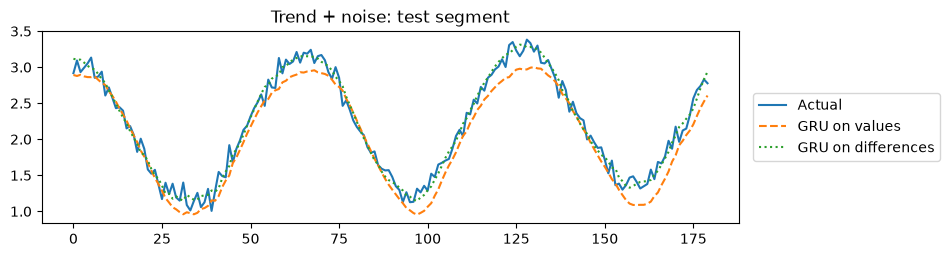

In [13]:
# [보강] 데이터 → 시간순 분할 → train 정규화 → 창 → 학습 → test 평가
def run_pipeline(noise, trend, diff=False):                      # 전체 파이프라인
    s = make_series(noise=noise, trend=trend)                    # 조건대로 시계열
    target = np.diff(s, prepend=s[0]) if diff else s             # 차분: 오늘 - 어제
    m_, sd_ = target[:n_tr].mean(), target[:n_tr].std()          # train 통계
    Xp, Yp, ip = make_windows((target - m_) / sd_, W)            # 정규화 → 창
    a, b, c = ip < n_tr, (ip >= n_tr) & (ip < n_va), ip >= n_va  # 시간순 분할
    model, _ = fit(Xp[a], Yp[a], Xp[b], Yp[b])                   # 학습
    p = predict(model, Xp[c])[:, 0] * sd_ + m_                   # 원래 단위
    if diff:                                                     # 차분이면
        p = s[ip[c] - 1] + p                                     # 어제 값 + 예측한 변화량
    return s[ip[c]], p, s[ip[c] - 1]                             # 정답 · 예측 · 직전 값


print("잡음  추세    방식      GRU MSE  직전 값 MSE")                    # 머리글
plots = {}                                                               # 그림용
for noise, trend, diff in [(0.05, 0, False), (0.2, 0, False),            # 조건 4가지
                           (0.1, 0.002, False), (0.1, 0.002, True)]:
    y_true, p, last = run_pipeline(noise, trend, diff)                   # 실행
    way = "차분" if diff else "값"                                       # 방식 이름
    print(f"{noise:<5} {trend:<6} {kpad(way, 8)}  {mse(p, y_true):.4f}"  # GRU · 기준선
          f"   {mse(last, y_true):.4f}")
    if trend:                                                            # 추세 조건만
        plots[way] = (y_true, p)                                         # 그림용 저장


# 추세가 있으면 test 값이 train 범위를 벗어남
trend_s = make_series(noise=0.1, trend=0.002)                 # 추세 있는 시계열
print(f"추세 있음 · train 최댓값 {trend_s[:n_tr].max():.2f}"  # 범위 비교
      f" · test 최댓값 {trend_s[n_va:].max():.2f}")


# 추세 있는 test 구간: 값 그대로 예측 vs 차분 예측
plt.figure(figsize=(9, 2.5))                                 # 가로로 긴 그림
plt.plot(plots["값"][0], label="Actual")                     # 실제
plt.plot(plots["값"][1], "--", label="GRU on values")        # 값 예측
plt.plot(plots["차분"][1], ":", label="GRU on differences")  # 차분 예측
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))    # 범례는 그림 밖 (선을 가리지 않게)
plt.title("Trend + noise: test segment")                     # 제목
plt.show()                                                   # 그림 출력

**결과** · 예측 정답은 못 이김 — GRU `0.0434` > 직전 값 `0.0255`, 차분으로 바꾸면 `0.0118`로 기준선의 절반 이하

- `0.05  0      값        0.0028   0.0101` — 잡음이 작으면 GRU가 기준선의 약 1/4
- `0.2   0      값        0.0422   0.0873` — 잡음이 크면 둘 다 나빠지지만 GRU가 기준선의 약 절반
- `0.1   0.002  값        0.0434   0.0255` — 추세가 있으면 값을 그대로 맞히는 GRU가 직전 값보다 나쁨
- `0.1   0.002  차분      0.0118   0.0255` — 변화량을 맞히게 바꾸면 직전 값보다 MSE 54% 낮음
- `추세 있음 · train 최댓값 2.74 · test 최댓값 3.38` — test가 train에서 본 적 없는 높이 → 값 모델이 실패한 이유

**해석**

- 같은 파이프라인이라도 **데이터 성질에 따라 결론이 뒤집힘**
- 잡음만 있을 때는 GRU가 늘 기준선을 이겼음
- 추세가 있으면 값 그대로는 기준선보다 나빴고, 차분으로 바꾸자 다시 이김
- 기준선이 없었다면 `0.0434`가 나쁜 점수인지 알 수 없었음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">값 그대로 예측</td>
<td style="text-align: left;">train 범위 안의 값만 잘 다룸</td>
<td style="text-align: left;">추세 없이 일정한 범위를 오가는 데이터</td>
</tr>
<tr>
<td style="text-align: left;">차분 예측 (<code>오늘 - 어제</code>)</td>
<td style="text-align: left;">변화량을 맞히고 어제 값에 더함</td>
<td style="text-align: left;">추세가 있어 미래 값이 train 범위를 벗어날 때</td>
</tr>
<tr>
<td style="text-align: left;">잡음이 큰 데이터</td>
<td style="text-align: left;">모델 · 기준선 모두 나빠짐</td>
<td style="text-align: left;">이동 평균 기준선 · MAE도 함께 보고</td>
</tr>
<tr>
<td style="text-align: left;">기준선 함께 보고</td>
<td style="text-align: left;">데이터가 바뀌어도 점수의 좋고 나쁨을 판단 가능</td>
<td style="text-align: left;"><strong>항상</strong></td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 차분으로 학습한 뒤 예측을 되돌릴 때 '어제 값'은 실제 관측값
> - 여러 걸음 예측이면 예측한 변화량을 차례로 누적해야 함

> ✅ **한 줄 정리** · 시간순 분할 · train 통계 · 기준선 비교를 고정해 두고 데이터 성질(잡음 · 추세)을 확인하며, 추세가 있으면 값 대신 변화량을 예측한다.

**딥러닝 코드에서는**

- 프로젝트 시계열(매출 · 센서 · 수요)도 먼저 그래프로 추세 · 주기를 봄
- `df["diff"] = df["value"].diff()`로 차분 열을 만든 뒤, 직전 값 · 이동 평균 기준선과 같은 표에 정리

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. 창 만들기</td>
<td style="text-align: left;">500칸 · 창 50 → <code>(450, 50, 1)</code>, NumPy <code>sliding_window_view</code> · Pandas <code>shift(-50)</code>과 일치</td>
<td style="text-align: left;">1-2</td>
</tr>
<tr>
<td style="text-align: left;">2. 시간순 분할</td>
<td style="text-align: left;">검증 정답이 학습 입력에 이미 있는 비율 무작위 <code>1.000</code> vs 시간순 <code>0.000</code></td>
<td style="text-align: left;">2-1</td>
</tr>
<tr>
<td style="text-align: left;">3. 정규화 · 기준선 · 지표</td>
<td style="text-align: left;">train 통계로 정규화, GRU <code>0.0107</code> vs 직전 값 <code>0.0255</code>, 튀는 오차 하나에 MSE 6.1배</td>
<td style="text-align: left;">2-2 · 3장</td>
</tr>
<tr>
<td style="text-align: left;">4. 여러 걸음 · window</td>
<td style="text-align: left;">20칸 뒤 MAE 재귀 <code>0.085</code> · 직접 <code>0.091</code> · 직전 값 고정 <code>1.069</code>, window 5는 <code>0.0167</code></td>
<td style="text-align: left;">4장</td>
</tr>
<tr>
<td style="text-align: left;">5. 추세 · 차분</td>
<td style="text-align: left;">값 예측 <code>0.0434</code>가 직전 값 <code>0.0255</code>보다 나쁨 → 차분 <code>0.0118</code></td>
<td style="text-align: left;">5장</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">딥러닝 코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">슬라이딩 윈도우</td>
<td style="text-align: left;">창 W칸 → 다음 값, 창 수 = 길이 - W</td>
<td style="text-align: left;"><code>X.shape == (N, W, 1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">수업 방식 평가</td>
<td style="text-align: left;">학습 데이터 점수 = 외운 정도</td>
<td style="text-align: left;">미래 구간 test로 보고</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">시간순 분할</td>
<td style="text-align: left;">정답 위치로 과거 → 미래, 섞지 않음</td>
<td style="text-align: left;"><code>shuffle=False</code> · 날짜로 자르기</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">정규화</td>
<td style="text-align: left;">train 통계로만, 되돌려서 평가</td>
<td style="text-align: left;"><code>(x - mu_tr) / sd_tr</code> · <code>* sd + mu</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">기준선</td>
<td style="text-align: left;">직전 값 · 이동 평균(어제까지)</td>
<td style="text-align: left;"><code>shift(1)</code> · <code>rolling(k).mean().shift(1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">여러 걸음</td>
<td style="text-align: left;">재귀 vs 직접, 걸음별 오차</td>
<td style="text-align: left;"><code>nn.Linear(hid, H)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">추세</td>
<td style="text-align: left;">범위를 벗어나면 차분</td>
<td style="text-align: left;"><code>df["value"].diff()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">사인파 · 주기</td>
<td style="text-align: left;">주기를 알아야 window 후보가 생김</td>
<td style="text-align: left;">하루 24칸 · 주 7칸</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">MSE vs MAE</td>
<td style="text-align: left;">큰 오차에 MSE가 크게 반응</td>
<td style="text-align: left;"><code>nn.MSELoss</code> · <code>nn.L1Loss</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">window</td>
<td style="text-align: left;">주기의 일부 이상, val로 고름</td>
<td style="text-align: left;">후보 여러 개 비교</td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">긴 시계열 하나를 어떻게 '과거 W칸 → 다음 1칸' 학습 데이터로 바꾸며, 창은 몇 개 나오는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">학습에 쓴 데이터로 잰 MSE는 무엇을 말해 주는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">시계열 창을 무작위로 나누면 무엇이 새어 들어가는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">정규화 통계는 어디서 계산하고, 예측은 어떻게 평가 단위로 되돌리는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">모델 점수는 무엇과 비교해야 하며, 이동 평균 기준선을 만들 때 주의할 점은?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">오차 하나가 크게 튀면 MSE와 MAE는 각각 어떻게 변하는가?</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">여러 걸음 예측의 두 가지 방법과 그 차이는?</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">window 길이는 무엇을 기준으로 정하는가?</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">추세가 있는 시계열에서 값 그대로 예측하면 왜 실패하며, 어떻게 고치는가?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

학습 없이 데이터 다루기만 확인하는 문제. **먼저 손으로 답을 적고** 아래 빈 셀에서 코드로 확인.

1. 길이 300인 시계열 `np.arange(300.0)`을 창 30칸으로 자르면 입력 · 정답 모양은? (`sliding_window_view`)
2. 1번 창의 정답 위치 `idx = np.arange(30, 300)`을 시간순 70% · 15% · 15%(경계 `int(300 * 0.70)` · `int(300 * 0.85)`)로 나누면 각각 몇 개?
3. `s = np.array([1.0, 2, 3, 4, 5, 6, 7, 20])`에서 앞 6개(train)로 평균 · 표준편차를 구해 정규화하면 마지막 값 20은 몇이 되고, 되돌리면?
4. 오차 `[0.1, -0.2, 0.1, 2.0]`의 MSE와 MAE
5. `pd.Series([1.0, 2, 3, 4, 5])`로 직전 값 기준선과 3칸 이동 평균 기준선(어제까지만) 만들기

In [14]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 길이 1000 시계열을 window 30 · 다음 5칸(직접 예측)으로 자르면 창은 몇 개인가?
2. 같은 길이 1000 · window 30(다음 1칸)을 정답 위치 기준 70% · 15% · 15%로 나누면 train · val · test 창 수는?
3. 오차 `[0.2, -0.2, 0.2, -0.2]`의 첫 값만 2.2로 바뀌면 MSE와 MAE는 각각 몇 배가 되는가?

In [15]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">창을 한 칸씩 밀며 W칸 = 입력, 바로 다음 칸 = 정답. 창 수 = 길이 - W, 모양 <code>(길이 - W, W, 1)</code></td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">외운 정도일 뿐 미래 성능이 아님. 시간순으로 떼어 둔 test로 평가</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">창끼리 49칸이 겹쳐 검증 정답 칸을 학습 창이 입력으로 이미 봄(이 실험 100%). 정답 위치 기준 시간순으로 나눔</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">train 구간에서만 계산해 val · test · 추론에 그대로 사용, 예측은 <code>× sd + mu</code>로 되돌려 원래 단위로 평가</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">직전 값 · 이동 평균 기준선과 같은 test · 같은 단위로. 이동 평균은 <code>shift(1)</code>로 어제까지만</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">MSE는 제곱이라 크게 뜀(실험 6.1배), MAE는 조금만(1.2배)</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">재귀(한 걸음 모델의 예측을 다시 입력)와 직접(출력 H개). 재귀는 오차가 쌓일 수 있고 직접은 길이가 고정</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">주기의 일부 이상을 볼 만큼, 후보를 val 점수로 비교 (test로 고르지 않음)</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">test 값이 train 범위를 벗어나 처음 보는 숫자가 됨. 변화량(차분)을 예측하고 어제 값에 더함</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
# 1. 창 수 = 300 - 30, 마지막 창은 정답이 없어 제외
s = np.arange(300.0)
win = sliding_window_view(s, 30)[:-1]
print(win.shape, s[30:].shape)  # (270, 30) (270,)

# 2. 정답 위치로 시간순 분할
idx = np.arange(30, 300)
n_tr, n_va = int(300 * 0.70), int(300 * 0.85)
tr, va = idx < n_tr, (idx >= n_tr) & (idx < n_va)
print(tr.sum(), va.sum(), (idx >= n_va).sum())  # 180 45 45

# 3. train 통계로 정규화 → 되돌리기
s = np.array([1.0, 2, 3, 4, 5, 6, 7, 20])
mu, sd = s[:6].mean(), s[:6].std()
z = (s - mu) / sd
back = round(z[-1] * sd + mu, 6)  # 되돌리기
print(round(mu, 2), round(sd, 3), round(z[-1], 2), back)  # 3.5 1.708 9.66 20.0

# 4. MSE vs MAE
err = np.array([0.1, -0.2, 0.1, 2.0])
print(round(np.mean(err ** 2), 4), round(np.mean(np.abs(err)), 4))  # 1.015 0.6

# 5. 직전 값 · 이동 평균 (어제까지만)
v = pd.Series([1.0, 2, 3, 4, 5])
print(v.shift(1).tolist())  # [nan, 1.0, 2.0, 3.0, 4.0]
print(v.rolling(3).mean().shift(1).tolist())  # [nan, nan, nan, 2.0, 3.0]
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">1000 - 30 - 5 + 1 = 966개 (정답 5칸이 끝까지 들어가는 시작점)</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">정답 위치 30 ~ 999 중 train 30 ~ 699 = 670개 · val 700 ~ 849 = 150개 · test 850 ~ 999 = 150개</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">MSE 0.04 → 1.24 (31배) · MAE 0.2 → 0.7 (3.5배)</td>
</tr>
</tbody>
</table>

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) 창을 섞어 train · val로 나눔</td>
<td style="text-align: left;">표 데이터처럼 생각함</td>
<td style="text-align: left;">정답 위치 기준 시간순 분할</td>
<td style="text-align: left;">검증 정답이 학습 입력에 들어 있지 않나?</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. 시계열 데이터는 학습 · 검증을 어떻게 나누나요?**
> - 섞지 않고 시간 순서대로 앞부분을 train, 다음을 validation, 마지막을 test로 둡니다.
> - 슬라이딩 윈도우로 만든 창은 이웃끼리 대부분 겹쳐서, 무작위로 나누면 검증 정답이 학습 창의 입력에 이미 들어가 누수가 됩니다.
> - 실제로 확인해 보니 무작위 분할에서는 검증 정답의 100%가 학습 입력에 있었고, 시간순 분할에서는 0%였습니다.

**Q2. 시계열 정규화에서 주의할 점은?**
> - 평균과 표준편차를 train 구간에서만 계산하고, 같은 값으로 validation · test
> - 추론 데이터를 변환합니다.
> - 전체 데이터로 계산하면 추세가 있을 때 미래 값이 평균에 섞여 평가가 실제보다 쉬워집니다.
> - 예측은 다시 원래 단위로 되돌려 MSE · MAE를 보고합니다.

**Q3. 시계열 모델의 성능은 어떻게 판단하나요?**
> - 직전 값을 그대로 쓰는 예측이나 이동 평균 같은 기준선을 같은 test 구간에서 함께 계산합니다.
> - 모델이 기준선을 확실히 넘어야 의미가 있고, 이동 평균은 shift로 어제까지만 쓰게 해서 정답이 섞이지 않게 합니다.
> - 지표는 MSE와 함께 이상치에 덜 민감한 MAE도 봅니다.

**Q4. 여러 시점 앞을 예측하는 방법은?**
> - 한 걸음 모델의 예측을 다시 입력에 붙여 반복하는 재귀 방식과, 출력층을 H개로 두고 한 번에 예측하는 직접 방식이 있습니다.
> - 재귀는 길이를 자유롭게 바꿀 수 있지만 오차가 쌓일 수 있고, 직접은 길이가 고정입니다.
> - 어느 쪽이든 걸음별 오차를 기준선과 함께 확인합니다.

**Q5. 추세가 있는 시계열에서 모델이 기준선보다 못하면 무엇을 의심하나요?**
> - test 값이 train에서 본 범위를 벗어났는지 먼저 확인합니다.
> - 값 자체를 맞히는 모델은 처음 보는 크기에 약해서, 오늘 값에서 어제 값을 뺀 차분을 예측하게 바꾸고 예측을 어제 값에 더해 되돌립니다.
> - 실험에서는 차분으로 바꾸자 MSE가 0.0434에서 0.0118로 줄어 직전 값 기준선보다 좋아졌습니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>np.linspace()</code> · <code>np.sin()</code></td>
<td style="text-align: left;">numpy</td>
<td style="text-align: left;">구간 n등분 · 사인 값</td>
<td style="text-align: left;">1-1 <code>x = np.linspace(0, seq_len, num_samples)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>sliding_window_view()</code></td>
<td style="text-align: left;">numpy.lib.stride_tricks</td>
<td style="text-align: left;">창 한 번에 만들기</td>
<td style="text-align: left;">1-2 <code>win = sliding_window_view(data, 50)[:-1]</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>pd.Series.shift(-k)</code> · <code>.dropna()</code></td>
<td style="text-align: left;">pandas</td>
<td style="text-align: left;">k칸 뒤 값 당기기 · 빈 값 제거</td>
<td style="text-align: left;">1-2 <code>target = pd.Series(data).shift(-50).dropna()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.tensor(..., dtype=torch.float32)</code> · <code>.unsqueeze(-1)</code></td>
<td style="text-align: left;">torch · Tensor 메서드</td>
<td style="text-align: left;">실수 텐서 · 특성 축 추가</td>
<td style="text-align: left;">1-2 <code>sequences = torch.tensor(np.array(sequences),</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.RNN(1, 20, 2, batch_first=True)</code> · <code>nn.MSELoss()</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">수업 모델 · 회귀 손실</td>
<td style="text-align: left;">1-3 <code>self.rnn = nn.RNN(input_size, hidden_size, num_lay…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>.to(DEV)</code> · <code>.cpu().numpy()</code></td>
<td style="text-align: left;">Tensor · Module 메서드</td>
<td style="text-align: left;">device 맞추기 · NumPy로 꺼내기</td>
<td style="text-align: left;">1-3 <code>preds = model(X_d).cpu().numpy()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>plt.plot()</code> · <code>plt.legend()</code></td>
<td style="text-align: left;">matplotlib.pyplot</td>
<td style="text-align: left;">선 그래프 · 범례</td>
<td style="text-align: left;">1-3 <code>plt.plot(data, label=...)</code> · <code>plt.legend()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>np.random.default_rng().normal()</code></td>
<td style="text-align: left;">numpy.random</td>
<td style="text-align: left;">재현 가능한 잡음</td>
<td style="text-align: left;">0 <code>rng.normal(0, noise, n)</code> (make_series)</td>
</tr>
<tr>
<td style="text-align: left;"><code>idx &lt; n_tr</code> (불리언 mask)</td>
<td style="text-align: left;">NumPy 비교 연산</td>
<td style="text-align: left;">정답 위치로 시간순 분할</td>
<td style="text-align: left;">2-1 <code>tr, va, te = idx &lt; n_tr, (idx &gt;= n_tr) &amp; (idx &lt; n_…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>np.random.default_rng(0).permutation()</code></td>
<td style="text-align: left;">numpy.random</td>
<td style="text-align: left;">무작위 분할 (비교용)</td>
<td style="text-align: left;">2-1 <code>perm = np.random.default_rng(0).permutation(pool)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>set.update(range())</code></td>
<td style="text-align: left;">set</td>
<td style="text-align: left;">학습 창이 본 칸 모으기</td>
<td style="text-align: left;">2-1 <code>seen.update(range(i - W, i))</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>.mean()</code> · <code>.std()</code> · <code>(x - mu) / sd</code></td>
<td style="text-align: left;">ndarray 메서드 · 연산</td>
<td style="text-align: left;">train 통계 정규화 · 되돌리기</td>
<td style="text-align: left;">2-2 <code>mu, sd = series[:n_tr].mean(), series[:n_tr].std()</code> · <code>z = (series - mu) / sd</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.GRU</code> · <code>nn.Linear</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">시계열 회귀 모델</td>
<td style="text-align: left;">0 <code>self.r = nn.GRU(1, hid, batch_first=True)</code> · <code>self.o = nn.Linear(hid, H)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>copy.deepcopy(model.state_dict())</code> · <code>load_state_dict()</code></td>
<td style="text-align: left;">copy · nn.Module</td>
<td style="text-align: left;">가장 좋은 epoch 가중치 저장 · 복원</td>
<td style="text-align: left;">0 <code>copy.deepcopy(model.state_dict())</code> · <code>model.load_state_dict(best[1])</code> (fit)</td>
</tr>
<tr>
<td style="text-align: left;"><code>.shift(1)</code> · <code>.rolling(k).mean()</code></td>
<td style="text-align: left;">pandas Series 메서드</td>
<td style="text-align: left;">직전 값 · 이동 평균 기준선</td>
<td style="text-align: left;">3-1 <code>base = {"직전 값": s.shift(1),</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.functional.mse_loss</code> · <code>nn.MSELoss</code> · <code>nn.L1Loss</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">MSE · MAE 손실</td>
<td style="text-align: left;">3-2 <code>for name, fn in [("MSELoss", nn.MSELoss(reduction=…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>np.mean((p - y) ** 2)</code> · <code>np.abs()</code> · <code>np.sqrt()</code></td>
<td style="text-align: left;">numpy</td>
<td style="text-align: left;">MSE · MAE · RMSE</td>
<td style="text-align: left;">3-2 <code>print(f"GRU   MSE {np.mean(err ** 2):.4f} · MAE {n…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>make_windows(z, W, H)</code></td>
<td style="text-align: left;">보강 공통 함수</td>
<td style="text-align: left;">다음 H칸 정답 만들기</td>
<td style="text-align: left;">4-1 <code>XH, YH, iH = make_windows(z, W, H)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>np.concatenate([Xc[:, 1:], p[:, None]], axis=1)</code></td>
<td style="text-align: left;">numpy</td>
<td style="text-align: left;">창을 한 칸 밀고 예측 붙이기 (재귀)</td>
<td style="text-align: left;">4-1 <code>Xc = np.concatenate([Xc[:, 1:], p[:, None]], axis=1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Linear(hid, H)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">다음 H칸을 한 번에 (직접)</td>
<td style="text-align: left;">0 <code>self.o = nn.Linear(hid, H)</code> · 4-1 <code>fit(..., H=H)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>np.repeat()</code></td>
<td style="text-align: left;">numpy</td>
<td style="text-align: left;">직전 값 고정 기준선</td>
<td style="text-align: left;">4-1 <code>naive = np.repeat(series[iH[teH] - 1][:, None], H,…</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">그래프로 추세 · 주기 먼저 보기</td>
<td style="text-align: left;">학습에 쓴 데이터로 성능 보고</td>
</tr>
<tr>
<td style="text-align: left;">정답 위치 기준 시간순 분할</td>
<td style="text-align: left;">창을 섞어 train · val 나누기</td>
</tr>
<tr>
<td style="text-align: left;">train 통계 저장 → 추론에도 같은 값</td>
<td style="text-align: left;">전체 데이터로 평균 · 표준편차</td>
</tr>
<tr>
<td style="text-align: left;">직전 값 · 이동 평균 기준선 함께</td>
<td style="text-align: left;">기준선 없이 MSE만 보고</td>
</tr>
<tr>
<td style="text-align: left;">이동 평균 기준선은 <code>shift(1)</code></td>
<td style="text-align: left;">오늘 값이 들어간 <code>rolling</code> 그대로</td>
</tr>
<tr>
<td style="text-align: left;">모델 · 데이터를 같은 device로</td>
<td style="text-align: left;">모델만 <code>.to(device)</code></td>
</tr>
<tr>
<td style="text-align: left;">epoch · window는 val로 고르기</td>
<td style="text-align: left;">test 점수 보고 다시 고치기</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">무작위 분할 vs 시간순 분할</td>
<td style="text-align: left;">창을 섞어 나눔 vs 과거 → 미래 순서</td>
<td style="text-align: left;">시계열은 시간순 (누수는 구조로 확인)</td>
</tr>
<tr>
<td style="text-align: left;">창 나누기 vs 학습 중 창 섞기</td>
<td style="text-align: left;">train · test 경계 vs train 안 배치 순서</td>
<td style="text-align: left;">경계는 시간순, 배치 순서는 섞어도 됨</td>
</tr>
<tr>
<td style="text-align: left;">train 통계 vs 전체 통계 정규화</td>
<td style="text-align: left;">미래 차단 vs 미래가 평균에 섞임</td>
<td style="text-align: left;">train 통계, 추론 때도 같은 값</td>
</tr>
<tr>
<td style="text-align: left;">학습 데이터 점수 vs test 점수</td>
<td style="text-align: left;">외운 정도 vs 처음 보는 미래</td>
<td style="text-align: left;">보고는 test</td>
</tr>
<tr>
<td style="text-align: left;">val vs test</td>
<td style="text-align: left;">epoch · window 고르기 vs 마지막 보고</td>
<td style="text-align: left;">test는 한 번만</td>
</tr>
<tr>
<td style="text-align: left;">직전 값 vs 이동 평균</td>
<td style="text-align: left;">어제 값 vs 최근 k칸 평균</td>
<td style="text-align: left;">둘 다 기준선, 모델은 둘 다 넘어야</td>
</tr>
<tr>
<td style="text-align: left;"><code>rolling(k).mean()</code> vs <code>.shift(1)</code> 붙이기</td>
<td style="text-align: left;">오늘 값 포함 vs 어제까지만</td>
<td style="text-align: left;">예측용 기준선은 <code>shift(1)</code> 필수</td>
</tr>
<tr>
<td style="text-align: left;">MSE vs MAE</td>
<td style="text-align: left;">제곱 vs 절댓값</td>
<td style="text-align: left;">이상치가 있으면 MAE도 함께 보고</td>
</tr>
<tr>
<td style="text-align: left;">한 걸음 vs 여러 걸음</td>
<td style="text-align: left;">다음 1칸 vs 다음 H칸</td>
<td style="text-align: left;">여러 걸음은 기준선이 급격히 나빠지는지 함께 비교</td>
</tr>
<tr>
<td style="text-align: left;">재귀 vs 직접</td>
<td style="text-align: left;">예측을 다시 입력 vs 출력 H개</td>
<td style="text-align: left;">길이가 고정이면 직접, 자유로우면 재귀</td>
</tr>
<tr>
<td style="text-align: left;">짧은 window vs 긴 window</td>
<td style="text-align: left;">최근만 vs 주기 전체</td>
<td style="text-align: left;">val로 고름</td>
</tr>
<tr>
<td style="text-align: left;">값 예측 vs 차분 예측</td>
<td style="text-align: left;">값 그대로 vs 변화량</td>
<td style="text-align: left;">추세가 있으면 차분</td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 3개를 새로 풀기 · 2-1 누수 비율을 직접 다시 계산</td>
<td style="text-align: left;">20분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;">다른 시계열(기온 · 매출 CSV)로 5장 파이프라인을 처음부터 다시 짜기</td>
<td style="text-align: left;">40분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제만 다시 풀기 · RNN-3 시작 전 2 · 3장 ✅ 줄만 읽기</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

- 레이어 실습의 사인파 예측(수업 · 빈 코드 셀 2칸 정답 작성)을 1장 3개 섹션으로 둠
- 수업 자료에 없는 **보강**(시간순 분할 · 정규화 · 기준선 · MSE vs MAE · 여러 걸음 · window)을 2 ~ 4장 6개 섹션으로 더함
- 5장 종합 실습에서 잡음 · 추세가 섞인 사인파로 전체 파이프라인 실행 · 데이터는 노트북 안에서 만듦
- 레이어 · 모양 설명은 RNN-1 참조로 대신함

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 딥러닝 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
<tr>
<td style="text-align: left;">보강</td>
<td style="text-align: left;">수업 자료에 없는 내용 — 장 제목의 <code>(보강)</code>, 섹션 출처의 <code>보강</code>, 코드 첫 줄의 <code># [보강]</code></td>
</tr>
</tbody>
</table>

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 예측 정답 · 결과 해설 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 = 이 단계에서 하는 일, 코드 옆 = 실행 흐름 · 문법 구조

**실행 환경** · 해설의 수치는 **GPU(CUDA) · torch 2.11 · seed 고정**으로 두 번 실행해 같은 값이 나온 것. GPU가 없으면 CPU로 실행되며 학습 결과 숫자가 조금 다를 수 있음

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">레이어 실습 (<code>RNN_03</code>)</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">맨 앞 빈 코드 셀</td>
<td style="text-align: left;"><strong>빈칸 1</strong> · 실행 준비 (라이브러리 · seed · device)</td>
<td style="text-align: left;">0장</td>
</tr>
<tr>
<td style="text-align: left;">RNN · LSTM · GRU 레이어 모양 · 요약표</td>
<td style="text-align: left;"><code>out</code> · <code>h_n</code> · <code>c_n</code> 모양</td>
<td style="text-align: left;">RNN-1 3-3 (<strong>참조</strong>, 이 노트북은 1-3 모양 흐름 표만)</td>
</tr>
<tr>
<td style="text-align: left;">시계열 데이터 실습 · <code>gen_sine_wave</code></td>
<td style="text-align: left;">사인파 500칸</td>
<td style="text-align: left;">1-1</td>
</tr>
<tr>
<td style="text-align: left;"><code>create_sequences</code></td>
<td style="text-align: left;">창 50칸 → 다음 값</td>
<td style="text-align: left;">1-2</td>
</tr>
<tr>
<td style="text-align: left;"><code>RNNModel</code> · 학습 · 예측 그래프</td>
<td style="text-align: left;">RNN 2층 · 100 epoch</td>
<td style="text-align: left;">1-3</td>
</tr>
<tr>
<td style="text-align: left;">맨 끝 빈 코드 셀</td>
<td style="text-align: left;"><strong>빈칸 2</strong> · 예측을 숫자(MSE)로 평가</td>
<td style="text-align: left;">1-3 끝</td>
</tr>
<tr>
<td style="text-align: left;">(보강)</td>
<td style="text-align: left;">시간순 분할 · 정규화 · 기준선 · MSE vs MAE · 여러 걸음 · window · 잡음 · 추세 실험</td>
<td style="text-align: left;">2-1 ~ 4-2 · 5장</td>
</tr>
</tbody>
</table>

**원본에서 고친 것**

- 모델만 `.to(device)`하고 데이터는 CPU에 둬서 GPU에서 `RuntimeError` · `X`
- `y`도 같은 device로, 예측은 `.cpu()` 후 `.numpy()` (1-3).
- 원본은 학습 데이터로 평가하므로 수업 그대로 두고, 미래 구간 평가는 보강(2 · 3장)으로 구분

### 전체 지도

#### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">배우는 이유</th>
<th style="text-align: left;">대단원</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">시계열 하나를 창으로 잘라 학습하는 수업 흐름을 그대로 실행한다</td>
<td style="text-align: left;">수업 · 사인파 한 걸음 예측</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">수업은 학습 데이터로 평가했다 → 미래를 떼어 두고, 미래 정보가 새지 않게 정규화한다</td>
<td style="text-align: left;">나누기와 정규화</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">떼어 둔 미래로 채점하고, 공짜 예측(기준선)과 비교한다</td>
<td style="text-align: left;">학습과 평가</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">여러 칸 앞 · 과거 길이를 바꿔 본다</td>
<td style="text-align: left;">예측 방식</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">잡음 · 추세를 바꿔 전체 파이프라인을 돌린다</td>
<td style="text-align: left;">종합 실습</td>
</tr>
</tbody>
</table>

#### 시계열 예측 파이프라인 · 각 대단원이 쓰이는 곳

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰이는 장</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">① 데이터 확인</td>
<td style="text-align: left;">길이 · 간격 · 주기 · 범위 · 추세</td>
<td style="text-align: left;">1-1 · 5장</td>
</tr>
<tr>
<td style="text-align: left;">② 시간순 분할</td>
<td style="text-align: left;">train → val → test, 섞지 않음</td>
<td style="text-align: left;">2-1</td>
</tr>
<tr>
<td style="text-align: left;">③ 정규화</td>
<td style="text-align: left;">train 통계로만, 추세가 있으면 차분</td>
<td style="text-align: left;">2-2 · 5장</td>
</tr>
<tr>
<td style="text-align: left;">④ 창 만들기</td>
<td style="text-align: left;">과거 W칸 → 다음 1칸 또는 H칸</td>
<td style="text-align: left;">1-2 · 4-1 · 4-2</td>
</tr>
<tr>
<td style="text-align: left;">⑤ 학습</td>
<td style="text-align: left;">val로 epoch · window 고르기</td>
<td style="text-align: left;">1-3 · 3-1</td>
</tr>
<tr>
<td style="text-align: left;">⑥ 평가</td>
<td style="text-align: left;">원래 단위로 되돌려 기준선과 비교, MSE · MAE</td>
<td style="text-align: left;">3-1 · 3-2 · 4-1</td>
</tr>
</tbody>
</table>

### 전체 코드

보강 파이프라인의 핵심(잡음 사인파 → 시간순 분할 → train 통계 정규화 → 창 → GRU 학습 → 직전 값과 test 비교)을 장별 셀로 모음.

- **위에서부터 이 셀들만 실행해도 동작**
- 각 출력 앞 `[번호]`가 장

In [16]:
import copy    # 가중치 복사
import random  # 파이썬 난수 (데이터 만들기)

import numpy as np     # 배열 계산
import pandas as pd    # shift · rolling 기준선 (Pandas 9-5)
import torch           # 텐서 · 자동 미분
import torch.nn as nn  # 층: RNN · LSTM · GRU · Linear

SEED = 20260912                            # 수업 코드와 같은 seed
torch.backends.cudnn.deterministic = True  # GPU에서도 매번 같은 계산 결과
torch.backends.cudnn.benchmark = False     # 실행마다 계산 방법이 바뀌지 않게
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 없으면 CPU


def set_seed(seed=SEED):     # seed를 한 번에 고정하는 함수
    random.seed(seed)        # 파이썬 random 고정
    np.random.seed(seed)     # NumPy 난수 고정
    torch.manual_seed(seed)  # CPU · GPU 난수 고정

In [17]:
# ---------- 1. 데이터: 잡음 섞인 사인파 ----------
rng = np.random.default_rng(0)                                     # 잡음 seed
series = np.sin(0.1 * np.arange(1200)) + rng.normal(0, 0.1, 1200)  # 잡음 사인파

In [18]:
# ---------- 2. 시간순 분할 · train 통계 정규화 · 창 ----------
n = len(series)                                                     # 1200
n_tr, n_va, W = int(n * 0.70), int(n * 0.85), 50                    # 분할 경계 · 창
mu, sd = series[:n_tr].mean(), series[:n_tr].std()                  # train 통계만
z = (series - mu) / sd                                              # 전체를 train 기준으로
idx = np.arange(W, n)                                               # 정답 위치
X = np.stack([z[i - W:i] for i in idx])[..., None]                  # (창 수, W, 1)
Y = z[idx][:, None]                                                 # (창 수, 1)
tr, va, te = idx < n_tr, (idx >= n_tr) & (idx < n_va), idx >= n_va  # 정답 위치로 시간순 분할
print("[2] train · val · test 창:", tr.sum(), va.sum(), te.sum())   # 분할 개수

[2] train · val · test 창: 790 180 180


In [19]:
# ---------- 3. GRU 학습 (val 기준 가장 좋은 epoch) ----------
class GRUNet(nn.Module):                           # GRU 회귀 모델
    def __init__(self, hid=32):                    # hidden 32
        super().__init__()                         # nn.Module 준비 (필수)
        self.r = nn.GRU(1, hid, batch_first=True)  # 값 하나짜리 입력
        self.o = nn.Linear(hid, 1)                 # 다음 값 1개

    def forward(self, x):          # 입력이 지나가는 길
        out, _ = self.r(x)         # 모든 칸 요약
        return self.o(out[:, -1])  # 마지막 칸 → 값


def t(a):                                                    # 배열 → 텐서
    return torch.tensor(a, dtype=torch.float32, device=DEV)  # 정답 텐서


set_seed()                                                      # 모델마다 같은 시작점
model = GRUNet().to(DEV)                                        # 새 모델
opt = torch.optim.Adam(model.parameters(), lr=5e-3)             # Adam
Xa, Ya, Xv, Yv = t(X[tr]), t(Y[tr]), t(X[va]), t(Y[va])         # train · val
best = (float("inf"), None)                                     # 가장 좋은 val
for epoch in range(100):                                        # 100 epoch
    model.train()                                               # 학습 모드
    perm = torch.randperm(len(Xa)).to(DEV)                      # 줄 순서 섞기
    for i in range(0, len(Xa), 64):                             # 64줄씩
        j = perm[i:i + 64]                                      # 이번 배치
        opt.zero_grad()                                         # 지난 기울기 지우기
        nn.functional.mse_loss(model(Xa[j]), Ya[j]).backward()  # MSE → 기울기
        opt.step()                                              # 가중치 한 걸음 수정
    model.eval()                                                # 평가 모드
    with torch.no_grad():                                       # 평가는 기울기 기록 안 함
        v = nn.functional.mse_loss(model(Xv), Yv).item()        # 이번 epoch val MSE
    if v < best[0]:                                             # 더 좋아졌으면
        best = (v, copy.deepcopy(model.state_dict()))           # 저장
model.load_state_dict(best[1])                                  # 가장 좋은 가중치로 되돌림

<All keys matched successfully>

In [20]:
# ---------- 3. test 평가: GRU vs 직전 값 기준선 (원래 단위) ----------
with torch.no_grad():                                         # 평가는 기울기 기록 안 함
    p = model(t(X[te])).cpu().numpy()[:, 0] * sd + mu         # test 예측 → 원래 단위
y_true = series[idx[te]]                                      # 정답
naive = pd.Series(series).shift(1).values[idx[te]]            # 직전 값
print(f"[3] test MSE · GRU {np.mean((p - y_true) ** 2):.4f}"  # 비교
      f" · 직전 값 {np.mean((naive - y_true) ** 2):.4f}")

[3] test MSE · GRU 0.0107 · 직전 값 0.0255
